# 9. Híbrido: BiLSTM con atención y descomposición

| | |
|---|---|
| **Entra** | `datasets/procesado/4_dataset_seleccion.csv` — objetivo, partición y orígenes |
| | `datasets/procesado/2_dataset_procesado.csv` — la serie diaria con la que se arma la ventana |
| | `datasets/procesado/5_predicciones_sarimax.csv`, `6_predicciones_xgboost.csv`, |
| | `7_predicciones_lstm.csv` y `8_predicciones_gru.csv` — las otras tres familias |
| | `resultados_modelos.csv` — de donde se leen sus cifras publicadas, sin copiarlas a mano |
| **Sale** | `9_predicciones_hibrido.csv`, `9_metricas_hibrido.csv`, `9_error_por_horizonte_hibrido.csv` |
| | `models/baseline/Hibrido/hibrido_base.keras` |
| | filas en `resultados_modelos.csv`, una por cada una de las tres lecturas |
| **Módulo** | `_resultados.py` |

## 1. Qué hace este notebook, y qué cierra

Entrena la cuarta y última familia de la comparación: los híbridos.

### 1.1 Qué es «híbrido» aquí, exactamente

Tres mecanismos sobre la misma red recurrente.

### 1.2 Lo que no se podrá separar

Los tres cambios entran juntos.

### 1.3 Por qué la red lee una ventana y no las 38 columnas

Los dos modelos anteriores leen una fila por origen con 38 columnas ya derivadas: rezagos de 1, 7, 14 y 30 días, medias móviles de 7 y 30, y diferencias de 1 y 30.

### 1.4 Y sin embargo no son datos distintos

La ventana no contiene *otra* información: contiene la misma, y la contiene toda.

In [1]:
# ============================================================
# 2. Configuración
# ============================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # silencia los avisos de compilación de TensorFlow

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

PROC = os.path.join("datasets", "procesado")
MODELOS = os.path.join("models", "baseline", "Hibrido")
os.makedirs(MODELOS, exist_ok=True)

HORIZONTE = 30                                    # días; el horizonte de mediano plazo del trabajo
VENTANA = 31                                      # días de historia que lee la red: [t-30, t]
PASO_WFV = 60                                     # cada cuántos orígenes se reajusta el modelo
SEMILLAS = [42, 7, 123, 2024, 99]                 # las mismas cinco de los notebooks 4 y 6

FIN_ENTRENAMIENTO = pd.Timestamp("2022-12-31")
INICIO_PRUEBA = pd.Timestamp("2023-02-01")        # entre medias, todo enero de 2023: el embargo

# Las cuatro variables continuas de la selección. El día de la semana entra aparte, como estática,
# porque no es una serie que la red deba recorrer.
VARS = ["precio_bolsa", "aportes_energia", "vertimientos", "gen_hidraulica"]

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.config.threading.set_intra_op_parallelism_threads(os.cpu_count())

# Determinismo: `set_random_seed` fija las semillas de Python, NumPy y TensorFlow, pero algunas
# operaciones de GPU y de CPU multihilo siguen siendo no deterministas por el orden en que suman.
# Sin esto, dos corridas con la misma semilla pueden dar cifras distintas en los últimos decimales,
# y un trabajo que se defiende tiene que poder reproducir sus números exactamente.
tf.config.experimental.enable_op_determinism()

print(f"TensorFlow {tf.__version__}  |  GPU: {tf.config.list_physical_devices('GPU') or 'ninguna, se usa CPU'}")
print(f"Ventana de {VENTANA} días x {len(VARS)} variables  ->  {HORIZONTE} salidas por origen")

# ============================================================
# La escala de pagina de las figuras
# ============================================================
# El documento inserta toda figura al ancho de su columna, 6.332.220 EMU = 6,92 pulgadas. Una
# figura dibujada a 13 pulgadas cabe ahi, pero ENCAJADA: todo su texto se reduce en la misma
# proporcion, y un cuerpo de 10 puntos acaba en 5,4 sobre el papel, que no se lee impreso.
#
# La resolucion del render EN LINEA no la fija el figsize ni savefig.dpi, sino la de la propia
# figura, que vale 100 mientras no se diga otra cosa: el backend en linea llama a print_figure
# con dpi=fig.dpi de forma explicita. Por eso `a_escala` la fija sobre la figura.
PPP_PAGINA, ANCHO_PX = 186, 1289
ANCHO_PAGINA = ANCHO_PX / PPP_PAGINA                     # 6,93 pulgadas

# EL RECORTE DEL BACKEND EN LINEA DESHACE ESTA ESCALA, y hay que desactivarlo. Por omision la
# figura se guarda con bbox_inches="tight", es decir ajustada a su contenido y no al tamano que se
# le dio: con letra pequena eso recorta unos pixeles de margen, pero con letra del cuerpo del
# documento los rotulos no caben en el lienzo y la imagen se ENSANCHA. Una imagen mas ancha
# insertada en el mismo ancho de columna tiene mas pixeles por pulgada, luego su letra se ve mas
# pequena: la rejilla de distribuciones pasaba de 1289 a 1633 pixeles y sus 10 puntos se veian a
# 7,9. Sin recorte, cada figura sale a ANCHO_PAGINA x PPP_PAGINA y un punto del dibujo es un punto
# del papel. El reparto del espacio lo hace `tight_layout`, que es lo que ya se llama.
try:
    get_ipython().run_line_magic(
        "config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass                                   # ejecutado como script: no hay backend en linea


def alto_pagina(ancho_viejo, alto_viejo):
    """El alto que conserva la proporcion de la figura al llevarla al ancho de la pagina."""
    return ANCHO_PAGINA * alto_viejo / ancho_viejo


def a_escala(fig, cuerpo=10.0):
    """Lleva la figura a la escala de la pagina: resolucion y tamaños de letra.

    EL CUERPO ES EL DEL DOCUMENTO, 10 puntos, y no uno menor. Una figura se inserta al ancho de
    la columna, de modo que a esta escala cada punto tipografico es un punto sobre el papel: si
    la figura se dibuja con letra de 7, el lector la ve a 7 junto a un texto de 10 y no la lee
    impresa. Los numeros de los ejes y la leyenda van al mismo cuerpo que el texto, sin descuento,
    y solo el titulo sube un punto por encima.

    LO QUE NO QUEPA CON ESA LETRA SOBRA DE LA FIGURA. El tamaño no se baja para que entre un
    rotulo largo; se acorta el rotulo, o se le da mas alto a la figura.

    Se llama ANTES de tight_layout, para que el reparto del espacio cuente ya con el tamaño
    definitivo del texto.
    """
    fig.set_dpi(PPP_PAGINA)
    for ax in fig.get_axes():
        ax.title.set_fontsize(cuerpo + 1.0)
        ax.xaxis.label.set_fontsize(cuerpo)
        ax.yaxis.label.set_fontsize(cuerpo)
        ax.tick_params(axis="both", labelsize=cuerpo)
        for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
            etiqueta.set_fontsize(cuerpo)
        leyenda = ax.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(cuerpo)
    return fig


TensorFlow 2.15.0  |  GPU: ninguna, se usa CPU
Ventana de 31 días x 4 variables  ->  30 salidas por origen


## 3. Los datos: la ventana, y la comprobación de que contiene lo mismo

Se leen dos archivos.

In [2]:
# ============================================================
# 3.1 Lectura de los dos archivos
# ============================================================
s = pd.read_csv(os.path.join(PROC, "4_dataset_seleccion.csv"),
                parse_dates=["fecha", "fecha_objetivo"])
diario = pd.read_csv(os.path.join(PROC, "2_dataset_procesado.csv"), parse_dates=["fecha"])
diario = diario[["fecha"] + VARS].set_index("fecha").asfreq("D")

assert ((s["fecha_objetivo"] - s["fecha"]).dt.days == HORIZONTE).all(), \
    "La fecha objetivo debe ser el origen + 30 días"
assert diario.notna().all().all(), "la serie diaria tiene huecos"
assert diario.index.min() <= s["fecha"].min() - pd.Timedelta(days=VENTANA - 1), \
    "la serie diaria no cubre la ventana del primer origen"

print(f"Orígenes del dataset:  {len(s)}  ({s['fecha'].min().date()} a {s['fecha'].max().date()})")
print(f"Serie diaria:        {len(diario)}  ({diario.index.min().date()} a {diario.index.max().date()})")
print(f"La ventana del primer origen empieza el "
      f"{(s['fecha'].min() - pd.Timedelta(days=VENTANA - 1)).date()}: cubierta.")

# --- escala logarítmica: la serie es multiplicativa (EDA, sección 3.4) ---
LOG = pd.DataFrame(index=diario.index)
for v in VARS:
    hay_ceros = (diario[v] == 0).any()
    LOG[v] = np.log1p(diario[v]) if hay_ceros else np.log(diario[v])
    print(f"  {v:<18} {'log1p' if hay_ceros else 'log  '}   "
          f"{'(%d días en cero)' % (diario[v] == 0).sum() if hay_ceros else ''}")

Orígenes del dataset:  5754  (2010-06-30 a 2026-03-31)
Serie diaria:        5964  (2010-01-01 a 2026-04-30)
La ventana del primer origen empieza el 2010-05-31: cubierta.
  precio_bolsa       log     
  aportes_energia    log     
  vertimientos       log1p   (2313 días en cero)
  gen_hidraulica     log     


In [3]:
# ============================================================
# 3.2 La ventana, el objetivo y las variables estáticas
# ============================================================
# La serie diaria del precio con cobertura completa: `precio_bolsa` de 2_dataset_procesado llega al
# 2026-04-30, que es el día 30 del último origen, de modo que los 30 horizontes existen para todos.
PRECIO = diario["precio_bolsa"]

origenes = pd.DatetimeIndex(s["fecha"])
pos = {f: i for i, f in enumerate(LOG.index)}
fila_de = np.array([pos[f] for f in origenes])

# VENTANAS[i] son los 31 días [t-30, t] del origen i, en logaritmo. Eje 1 = tiempo, eje 2 = variable.
VENTANAS = np.stack([LOG.values[i - VENTANA + 1:i + 1] for i in fila_de]).astype("float64")

# REALES[i, h-1] es el precio OBSERVADO del día t+h del origen i.
REALES = np.column_stack([PRECIO.reindex(origenes + pd.Timedelta(days=h)).values
                          for h in range(1, HORIZONTE + 1)])

# El objetivo que la red aprende: el cambio logarítmico de cada uno de los 30 días respecto del
# precio del origen. Es la misma formulación relativa del notebook 6, extendida a 30 salidas.
Z = np.log(REALES / s["precio_hoy"].values[:, None])

# Estáticas: el día de la semana del ORIGEN en siete indicadoras, y el indicador de vertimientos.
# Con una salida por horizonte, la red puede representar el efecto del día de la semana de cada día
# objetivo, porque el día de la semana de t+h se deduce del de t y de h.
DOW = pd.get_dummies(origenes.dayofweek, prefix="dow").values.astype("float64")
ESTATICAS = np.column_stack([DOW, s["vertimientos_ind"].values]).astype("float64")

assert not np.isnan(VENTANAS).any(), "hay huecos en las ventanas"
assert not np.isnan(REALES).any(), "faltan precios observados"
assert not np.isnan(Z).any(), "faltan valores del objetivo"
print(f"VENTANAS  {VENTANAS.shape}   (orígenes x días x variables)")
print(f"ESTATICAS {ESTATICAS.shape}   (7 indicadoras de día de la semana + vertimientos_ind)")
print(f"Z         {Z.shape}   (el objetivo: log del cambio de cada uno de los 30 días)")
print(f"REALES    {REALES.shape}   (el precio observado de cada uno de los 30 días)")

VENTANAS  (5754, 31, 4)   (orígenes x días x variables)
ESTATICAS (5754, 8)   (7 indicadoras de día de la semana + vertimientos_ind)
Z         (5754, 30)   (el objetivo: log del cambio de cada uno de los 30 días)
REALES    (5754, 30)   (el precio observado de cada uno de los 30 días)


### 3.3 La comprobación de paridad

Antes de entrenar nada, el notebook comprueba que la ventana **contiene** las columnas que leen los otros dos modelos.

In [4]:
# ============================================================
# 3.3 ¿La ventana contiene las 38 columnas que leen los otros modelos?
# ============================================================
NO_PREDICTORAS = ["fecha", "fecha_objetivo", "precio_hoy", "objetivo", "objetivo_dia30",
                  "indice_ONI_publicado"]
COLS_ARBOLES = [c for c in s.columns if c not in NO_PREDICTORAS]


def reconstruir(i):
    """Las derivadas del origen i, calculadas SOLO desde su ventana de 31 días.

    Se trabaja sobre el NIVEL y no sobre el logaritmo, porque las columnas del dataset están en
    nivel: la escala logarítmica es una transformación de la entrada de la red, no de los datos.
    """
    out = {}
    for c in VARS:
        col = diario[c].values[fila_de[i] - VENTANA + 1:fila_de[i] + 1]   # col[30] = día del origen
        out[c] = col[30]
        out[f"{c}_lag1"], out[f"{c}_lag7"] = col[29], col[23]
        out[f"{c}_lag14"], out[f"{c}_lag30"] = col[16], col[0]
        out[f"{c}_ma7"] = col[23:30].mean()      # [t-7, t-1]: la media termina el día anterior
        out[f"{c}_ma30"] = col[0:30].mean()      # [t-30, t-1]
        out[f"{c}_dif1"] = col[30] - col[29]
        out[f"{c}_dif30"] = col[30] - col[0]
    return out


rng = np.random.default_rng(7)
muestra = rng.choice(len(s), size=300, replace=False)
peor = {}
for i in muestra:
    rec = reconstruir(i)
    for c, valor in rec.items():
        real = float(s[c].iloc[i])
        peor[c] = max(peor.get(c, 0.0), abs(real - valor) / max(abs(real), 1.0))

reconstruidas = sorted(peor)
no_reconstruidas = sorted(set(COLS_ARBOLES) - set(reconstruidas))
print(f"Comprobado sobre 300 orígenes al azar, ventana de {VENTANA} días x {len(VARS)} variables:")
print(f"  columnas reconstruidas desde la ventana: {len(reconstruidas)} de {len(COLS_ARBOLES)}")
print(f"  error relativo máximo: {max(peor.values()):.2e}")
print(f"  columnas que la ventana no da ({len(no_reconstruidas)}): {no_reconstruidas}")

assert max(peor.values()) < 1e-8, "la ventana NO reproduce las columnas del dataset"
assert set(no_reconstruidas) <= {"dia_semana_obj", "vertimientos_ind"}, \
    "la ventana deja fuera alguna columna que no es estática"
print("\nLa ventana contiene la misma información que las 38 columnas, sin agregar. Las dos que no")
print("da son el día de la semana y el indicador de vertimientos, y entran como estáticas.")

Comprobado sobre 300 orígenes al azar, ventana de 31 días x 4 variables:
  columnas reconstruidas desde la ventana: 36 de 38
  error relativo máximo: 1.81e-10
  columnas que la ventana no da (2): ['dia_semana_obj', 'vertimientos_ind']

La ventana contiene la misma información que las 38 columnas, sin agregar. Las dos que no
da son el día de la semana y el indicador de vertimientos, y entran como estáticas.


### 3.4 La descomposición de la ventana

Aquí entra el primero de los tres mecanismos.

| Componente | Cómo |
|---|---|
| Tendencia | media móvil de 7 días **hacia atrás**; en los seis primeros días de la ventana, media expansiva |
| Estacionalidad | perfil semanal de la serie ya detendenciada, centrado a media cero |
| Residuo | lo que queda: `ventana − tendencia − estacionalidad`, exacto por construcción |

In [5]:
# ============================================================
# 3.4 La descomposición: tendencia, estacionalidad semanal y residuo
# ============================================================
def descomponer(V, dow_origen):
    # V es (n, 31, k) en logaritmo; dow_origen, el día de la semana del origen de cada ventana.
    # NO PUEDE HABER FUGA: la función solo recibe los 31 días de la ventana, todos observados.
    n, T, k = V.shape

    # Tendencia: media móvil de 7 días HACIA ATRÁS. En los seis primeros días no hay siete, y se usa
    # la media expansiva: así queda definida en todas las posiciones sin mirar adelante ni una vez.
    tend = np.empty_like(V)
    for p in range(T):
        tend[:, p] = V[:, max(0, p - 6):p + 1].mean(axis=1)

    # Estacionalidad: el perfil semanal de lo que queda. El día de la semana de la posición p se
    # deduce del origen: la posición T-1 ES el origen, y cada paso atrás resta un día.
    dsem = (dow_origen[:, None] - (T - 1 - np.arange(T))[None, :]) % 7          # (n, T)
    det = V - tend
    est = np.zeros_like(V)
    for d in range(7):
        m = (dsem == d)
        est += m[:, :, None] * ((det * m[:, :, None]).sum(axis=1)
                                / m.sum(axis=1)[:, None])[:, None, :]
    est -= est.mean(axis=1, keepdims=True)      # centrada: la estacionalidad no aporta nivel

    return tend, est, V - tend - est


TEND, EST, RES = descomponer(VENTANAS, origenes.dayofweek.values)

# La entrada de la red: los tres componentes de cada variable, en orden variable-mayor.
VENTANAS_D = np.concatenate([np.stack([TEND[:, :, j], EST[:, :, j], RES[:, :, j]], axis=2)
                             for j in range(len(VARS))], axis=2)
CANALES = [f"{v}_{c}" for v in VARS for c in ("tendencia", "estacional", "residuo")]
assert VENTANAS_D.shape == (len(s), VENTANA, len(CANALES)), VENTANAS_D.shape

# --- 1. exacta: los tres componentes suman la ventana original ---
assert np.allclose(TEND + EST + RES, VENTANAS, atol=1e-12), "la descomposición no es exacta"
# --- 2. la estacionalidad no aporta nivel ---
assert np.abs(EST.mean(axis=1)).max() < 1e-12, "la estacionalidad no quedó centrada"
# --- 3. recupera un perfil semanal conocido sobre una ventana sintética ---
_perf = np.array([0.5, -0.2, -0.1, 0.0, 0.1, 0.2, -0.5])        # suma cero
_dw = (3 - (VENTANA - 1 - np.arange(VENTANA))) % 7              # un origen en miércoles
_sint = (0.01 * np.arange(VENTANA) + _perf[_dw])[None, :, None]
_a, _b, _c = descomponer(_sint, np.array([3]))
# Donde la media móvil ya usa siete días completos, el detendenciado es el perfil EXACTO salvo una
# constante: la media de siete días anula un perfil que suma cero.
_d7 = (_sint - _a)[0, 6:, 0]
_e7 = _perf[_dw][6:]
assert np.allclose(_d7 - _d7.mean(), _e7 - _e7.mean(), atol=1e-10), \
    "el detendenciado no deja el perfil semanal donde la media móvil es completa"
# El componente estacional sí queda aproximado, porque promedia también las seis primeras
# posiciones, donde la media es parcial. Se mide el error en vez de suponerlo.
_err = np.abs(_b[0, :, 0] - (_perf[_dw] - _perf[_dw].mean())).max()
print(f"Prueba sintética: el perfil semanal se recupera con error máximo {_err:.4f}")
print(f"  (el perfil vale entre {_perf.min():.1f} y {_perf.max():.1f}; el error viene de los seis")
print("   primeros días de la ventana, donde la media móvil es parcial)")
assert _err < 0.1, f"la descomposición no recupera un perfil semanal conocido: error {_err:.3f}"

print(f"\nVENTANAS_D {VENTANAS_D.shape}   (orígenes x días x {len(CANALES)} canales)")
print(f"{'variable':<20}{'σ tendencia':>13}{'σ estacional':>14}{'σ residuo':>11}")
for j, v in enumerate(VARS):
    print(f"{v:<20}{TEND[:, :, j].std():>13.4f}{EST[:, :, j].std():>14.4f}{RES[:, :, j].std():>11.4f}")
print("\nLa estacionalidad es pequeña frente a la tendencia en las cuatro variables: era de esperar")
print("en series diarias de un sistema eléctrico, y es justo el trabajo que la red no tendrá que")
print("hacer. El residuo es lo que queda por explicar, y es donde está la señal de corto plazo.")

Prueba sintética: el perfil semanal se recupera con error máximo 0.0186
  (el perfil vale entre -0.5 y 0.5; el error viene de los seis
   primeros días de la ventana, donde la media móvil es parcial)

VENTANAS_D (5754, 31, 12)   (orígenes x días x 12 canales)
variable              σ tendencia  σ estacional  σ residuo
precio_bolsa               0.7194        0.0672     0.1412
aportes_energia            0.4540        0.0718     0.1795
vertimientos               7.3315        1.1729     2.9676
gen_hidraulica             0.1793        0.0589     0.0503

La estacionalidad es pequeña frente a la tendencia en las cuatro variables: era de esperar
en series diarias de un sistema eléctrico, y es justo el trabajo que la red no tendrá que
hacer. El residuo es lo que queda por explicar, y es donde está la señal de corto plazo.


## 4. La partición, el embargo y los pliegues

Idénticos a los de los notebooks 4, 5 y 6.

In [6]:
# ============================================================
# 4. Partición, embargo y pliegues de validación
# ============================================================
EN_EMBARGO = ((s["fecha"] > FIN_ENTRENAMIENTO) & (s["fecha"] < INICIO_PRUEBA)).values
es_prueba = (s["fecha"] >= INICIO_PRUEBA).values
es_entren = (s["fecha"] <= FIN_ENTRENAMIENTO).values

dias_embargo = int(EN_EMBARGO.sum())
assert dias_embargo >= HORIZONTE, f"embargo de {dias_embargo} días < horizonte de {HORIZONTE}"

I_PRUEBA = np.where(es_prueba)[0]
ORIGENES_PRUEBA = origenes[I_PRUEBA]
print(f"Entrenamiento: {es_entren.sum():5d} orígenes  ({origenes[es_entren].min().date()} a "
      f"{origenes[es_entren].max().date()})")
print(f"Embargo:       {dias_embargo:5d} días       (todo enero de 2023, de ningún bloque)")
print(f"Prueba:        {len(I_PRUEBA):5d} orígenes  ({ORIGENES_PRUEBA.min().date()} a "
      f"{ORIGENES_PRUEBA.max().date()})")
assert len(I_PRUEBA) == 1155, f"se esperaban 1.155 orígenes de prueba, hay {len(I_PRUEBA)}"

# Los cinco pliegues de validación, los mismos del notebook 4
PLIEGUES = [("2012-12-31", "2013-01-01", "2014-12-31"),
            ("2014-12-31", "2015-01-01", "2016-12-31"),
            ("2016-12-31", "2017-01-01", "2018-12-31"),
            ("2018-12-31", "2019-01-01", "2020-12-31"),
            ("2020-12-31", "2021-01-01", "2022-12-31")]
print("\nPliegues de validación (ajuste hasta / validación desde / hasta):")
for k, (a, b, c) in enumerate(PLIEGUES, start=1):
    n_v = int(((origenes >= pd.Timestamp(b)) & (origenes <= pd.Timestamp(c))).sum())
    n_a = int(((s["fecha_objetivo"] <= pd.Timestamp(a)).values & ~EN_EMBARGO).sum())
    print(f"  P{k}: ajuste <= {a} ({n_a:5d} orígenes)   validación {b} a {c} ({n_v} orígenes)")

# El tamaño del conjunto de ajuste importa para esta familia, y conviene tenerlo a la vista: los
# pliegues ajustan con mucho menos que los bloques de la prueba, y una red sobreajusta antes cuanto
# menos tiene. La sección 7 vuelve sobre esto al elegir el número de épocas.
n_pliegues = [int(((s["fecha_objetivo"] <= pd.Timestamp(a)).values & ~EN_EMBARGO).sum())
              for a, _, _ in PLIEGUES]
print(f"\nEl conjunto de ajuste crece de {min(n_pliegues)} a {max(n_pliegues)} orígenes entre el "
      f"primer pliegue y el quinto.")
print(f"Los bloques de la validación progresiva ajustan con más: desde "
      f"{int(((s['fecha_objetivo'] < ORIGENES_PRUEBA[0]).values & ~EN_EMBARGO).sum())} orígenes.")

Entrenamiento:  4568 orígenes  (2010-06-30 a 2022-12-31)
Embargo:          31 días       (todo enero de 2023, de ningún bloque)
Prueba:         1155 orígenes  (2023-02-01 a 2026-03-31)

Pliegues de validación (ajuste hasta / validación desde / hasta):
  P1: ajuste <= 2012-12-31 (  886 orígenes)   validación 2013-01-01 a 2014-12-31 (730 orígenes)
  P2: ajuste <= 2014-12-31 ( 1616 orígenes)   validación 2015-01-01 a 2016-12-31 (731 orígenes)
  P3: ajuste <= 2016-12-31 ( 2347 orígenes)   validación 2017-01-01 a 2018-12-31 (730 orígenes)
  P4: ajuste <= 2018-12-31 ( 3077 orígenes)   validación 2019-01-01 a 2020-12-31 (731 orígenes)
  P5: ajuste <= 2020-12-31 ( 3808 orígenes)   validación 2021-01-01 a 2022-12-31 (730 orígenes)

El conjunto de ajuste crece de 886 a 3808 orígenes entre el primer pliegue y el quinto.
Los bloques de la validación progresiva ajustan con más: desde 4568 orígenes.


In [7]:
# ============================================================
# 5. Las referencias ingenuas
# ============================================================
# Se recalculan aquí sobre los mismos orígenes en vez de leerlas de otro sitio: si dos notebooks
# hubieran construido la partición de forma distinta, sus referencias no coincidirían y se vería.
from _resultados import lecturas as tres_lecturas, metricas

PERSIST = np.repeat(s["precio_hoy"].values[I_PRUEBA][:, None], HORIZONTE, axis=1)
MEDIA_TR = float(s["objetivo"].values[es_entren].mean())

REF = {"Referencia: persistencia (P de hoy)": tres_lecturas(PERSIST, REALES[I_PRUEBA]),
       "Referencia: media del entrenamiento": tres_lecturas(
           np.full_like(PERSIST, MEDIA_TR), REALES[I_PRUEBA])}
tabla_ref = pd.DataFrame([dict(configuracion=n, **v["promedio_30d"]) for n, v in REF.items()])
print("Sobre el promedio del mes:")
print(tabla_ref.round(2).to_string(index=False))

esperado = {"pares_30d": 178.37, "promedio_30d": 145.66, "dia_30": 239.27}
for clave, v in esperado.items():
    obtenido = REF["Referencia: persistencia (P de hoy)"][clave]["MAE"]
    assert abs(obtenido - v) < 0.01, \
        f"la persistencia en {clave} da {obtenido:.2f} y los notebooks 5, 6, 7 y 8 dan {v}"
print("\nLas tres lecturas de la persistencia coinciden con las de los notebooks 5, 6, 7 y 8:")
print("  pares 178,37  |  promedio del mes 145,66  |  día 30 239,27")
print("La partición es la misma, de modo que las cifras son comparables.")

Sobre el promedio del mes:
                      configuracion    MAE   RMSE  SMAPE
Referencia: persistencia (P de hoy) 145.66 232.21  30.54
Referencia: media del entrenamiento 292.57 421.42  69.83

Las tres lecturas de la persistencia coinciden con las de los notebooks 5, 6, 7 y 8:
  pares 178,37  |  promedio del mes 145,66  |  día 30 239,27
La partición es la misma, de modo que las cifras son comparables.


## 6. El modelo

### 6.1 La arquitectura

```
ventana descompuesta (31, 12)
        │
        ├──> BiLSTM(u, return_sequences) ──> 31 estados de 2u
        │                                          │
        │                            ┌─────────────┴─────────────┐
        │                            │  atención: un peso por    │
        │                            │  día, softmax sobre los 31│
        │                            └─────────────┬─────────────┘
        │                                          │
        └──────────────────────────> contexto = Σ αₜ·hₜ  ──┐
                                                            ├──> concatenar ──> Dense(30)
estáticas (8) ─────────────────────────────────────────────┘
```

La BiLSTM recorre los 31 días en los dos sentidos y, en vez de entregar solo el último estado, entrega los 31.

### 6.2 El escalador, que es donde se esconde una fuga

Una red necesita entradas normalizadas.

In [8]:
# ============================================================
# 6. La arquitectura, el escalador y la validación progresiva
# ============================================================
def construir_modelo(unidades=16, dropout=0.0, tasa=1e-3, semilla=42):
    """BiLSTM con atención sobre la ventana DESCOMPUESTA + estáticas -> 30 salidas."""
    tf.keras.utils.set_random_seed(semilla)
    e_seq = keras.Input(shape=(VENTANA, VENTANAS_D.shape[2]), name="ventana")
    e_est = keras.Input(shape=(ESTATICAS.shape[1],), name="estaticas")
    # Bidireccional y con return_sequences. Lo primero no es fuga: la ventana entera está observada
    # el día del pronóstico, de modo que recorrerla también de atrás hacia adelante usa pasado, no
    # futuro. Lo segundo es necesario: la atención necesita los 31 estados para ponderarlos.
    H = layers.Bidirectional(layers.LSTM(unidades, dropout=dropout, return_sequences=True),
                             name="bilstm")(e_seq)
    # Atención aditiva: una puntuación por día, normalizada con softmax SOBRE EL EJE DEL TIEMPO.
    a = layers.Dense(unidades, activation="tanh", name="atencion_oculta")(H)
    a = layers.Dense(1, use_bias=False, name="atencion_puntaje")(a)
    alfa = layers.Softmax(axis=1, name="atencion")(a)
    # El contexto: la suma de los 31 estados ponderada por la atención.
    h = layers.Concatenate()([layers.Flatten()(layers.Dot(axes=1)([alfa, H])), e_est])
    salida = layers.Dense(HORIZONTE, name="cambio_log")(h)
    modelo = keras.Model([e_seq, e_est], salida)
    modelo.compile(optimizer=keras.optimizers.Adam(tasa), loss="mae")
    return modelo


def escalar(i_ajuste, i_evalua):
    """Estandariza las ventanas con la media y la desviación DEL CONJUNTO DE AJUSTE."""
    # Se escala la ventana DESCOMPUESTA, canal por canal: la tendencia y el residuo tienen escalas
    # muy distintas, y normalizar los doce juntos aplastaría los dos componentes pequeños.
    plano = VENTANAS_D[i_ajuste].reshape(-1, len(CANALES))
    mu, sd = plano.mean(axis=0), plano.std(axis=0)
    assert (sd > 0).all(), \
        f"canal constante en el conjunto de ajuste: {[CANALES[j] for j in np.where(sd == 0)[0]]}"
    return (((VENTANAS_D[i_ajuste] - mu) / sd).astype("float32"),
            ((VENTANAS_D[i_evalua] - mu) / sd).astype("float32"))


def ajustar_predecir(params, i_ajuste, i_evalua, semilla, epocas):
    """Entrena sobre `i_ajuste` y devuelve los PRECIOS pronosticados de `i_evalua`, (n x 30)."""
    X_aj, X_ev = escalar(i_ajuste, i_evalua)
    modelo = construir_modelo(semilla=semilla, **params)
    modelo.fit([X_aj, ESTATICAS[i_ajuste].astype("float32")], Z[i_ajuste].astype("float32"),
               epochs=epocas, batch_size=64, verbose=0, shuffle=True)
    z = modelo.predict([X_ev, ESTATICAS[i_evalua].astype("float32")], verbose=0)
    return s["precio_hoy"].values[i_evalua][:, None] * np.exp(z), modelo


def indices_ajuste(corte):
    """Lo observable el día `corte`: purga de 30 días y embargo permanente de enero de 2023.

    Filtra por `fecha_objetivo`, no por `fecha`: solo entran los orígenes cuya ventana de treinta
    días ya terminó antes del corte. Es la misma condición de los notebooks 5, 6, 7 y 8.
    """
    return np.where((s["fecha_objetivo"] < corte).values & ~EN_EMBARGO)[0]


def walk_forward(params, semilla, epocas, i_objetivo=None, traza=False):
    """Pronostica los orígenes de `i_objetivo` reajustando cada PASO_WFV orígenes."""
    i_obj = I_PRUEBA if i_objetivo is None else i_objetivo
    pred = np.full((len(i_obj), HORIZONTE), np.nan)
    filas, ultimo = [], None
    for ini in range(0, len(i_obj), PASO_WFV):
        tramo = i_obj[ini:ini + PASO_WFV]
        corte = origenes[tramo[0]]
        i_aj = indices_ajuste(corte)
        p, ultimo = ajustar_predecir(params, i_aj, tramo, semilla, epocas)
        pred[ini:ini + len(tramo)] = p
        filas.append({"primer_origen": corte.date(), "n_ajuste": len(i_aj),
                      "ajuste_hasta": origenes[i_aj].max().date(), "n_pronosticos": len(tramo)})
    return (pred, pd.DataFrame(filas), ultimo) if traza else pred


# Traza de un solo bloque: comprueba que el primer ajuste cierra ANTES del embargo
t0 = time.time()
_, traza, _ = walk_forward(dict(unidades=16), 42, epocas=5, i_objetivo=I_PRUEBA[:60], traza=True)
print(f"Prueba de mecánica ({time.time() - t0:.0f} s, 5 épocas solo para comprobar el montaje):")
print(traza.to_string(index=False))
assert pd.Timestamp(traza.loc[0, "ajuste_hasta"]) <= FIN_ENTRENAMIENTO, \
    "el primer ajuste entra en el embargo"
print(f"\nEl primer ajuste cierra en {traza.loc[0, 'ajuste_hasta']}: enero de 2023 queda fuera.")

Prueba de mecánica (17 s, 5 épocas solo para comprobar el montaje):
primer_origen  n_ajuste ajuste_hasta  n_pronosticos
   2023-02-01      4568   2022-12-31             60

El primer ajuste cierra en 2022-12-31: enero de 2023 queda fuera.


## 7. La rejilla y la condición de utilidad

El criterio es el de los notebooks 4 y 6: la razón entre el MAE del modelo y el de la persistencia en cada pliegue, medida sobre el promedio del mes, y la **condición de utilidad** de superar a la persistencia en….

### El número de épocas importa mucho más que el tamaño de la red

La rejilla se recorre de una forma que conviene explicar, porque abarata el cómputo y además deja a la vista el hallazgo.

In [9]:
# ============================================================
# 7. Rejilla sobre los cinco pliegues, con la condición de utilidad
# ============================================================
# Las UNIDADES sí cambian respecto de los notebooks 7 y 8, con razón declarada: una capa
# bidireccional de u unidades tiene un estado de 2u, de modo que «16» aquí es el punto de ESTADO
# equiparado con la LSTM de 32 del notebook 7, y «8» queda claramente por debajo. El conteo de
# abajo muestra que las dos configuraciones tienen MENOS parámetros que esa LSTM: este notebook
# cambia el mecanismo sin añadir capacidad, que es lo que hace interpretable el resultado.
# Los CORTES DE ÉPOCAS, en cambio, son los mismos seis: recortarlos a la región donde la LSTM fue
# bien ensuciaría la comparación entre arquitecturas.
ARQUITECTURAS = [("BiLSTM 8 atención", dict(unidades=8)),
                 ("BiLSTM 16 atención", dict(unidades=16)),
                 ("BiLSTM 16 atención dropout 0,2", dict(unidades=16, dropout=0.2))]
CORTES = [3, 5, 10, 15, 30, 60]          # las épocas a las que se evalúa, igual que en 7 y 8


# El conteo de parámetros se MIDE, para que «equiparado» sea verificable y no una afirmación. Se
# arma además la red de los notebooks 7 y 8 sobre su entrada de 4 canales, solo para contar.
def _ref(celda, canales, u=32):
    tf.keras.utils.set_random_seed(0)
    a, b = keras.Input(shape=(VENTANA, canales)), keras.Input(shape=(ESTATICAS.shape[1],))
    h = layers.Concatenate()([celda(u)(a), b])
    return keras.Model([a, b], layers.Dense(HORIZONTE)(h)).count_params()


print("Parámetros de cada arquitectura, con su número de canales de entrada:")
for _et, _kw in ARQUITECTURAS:
    print(f"  {_et:<32} {len(CANALES):>3} canales  {construir_modelo(**_kw).count_params():>7}")
print(f"  {'LSTM 32 (notebook 7)':<32} {len(VARS):>3} canales  {_ref(layers.LSTM, len(VARS)):>7}")
print(f"  {'GRU 32 (notebook 8)':<32} {len(VARS):>3} canales  {_ref(layers.GRU, len(VARS)):>7}")
print("\nEl estado de «BiLSTM 16» es de 32, el mismo de la LSTM de 32; el de «BiLSTM 8», de 16.")
_n_max = max(construir_modelo(**_kw).count_params() for _, _kw in ARQUITECTURAS)
_n_lstm = _ref(layers.LSTM, len(VARS))
print(f"La configuración más grande de aquí tiene {_n_max} parámetros, y la LSTM del notebook 7, "
      f"{_n_lstm}.")
print("Este notebook cambia el MECANISMO sin añadir capacidad, y eso es lo que hace interpretable")
print("el resultado: si el híbrido mejora, no será por tener una red más grande.")
assert _n_max < _n_lstm, \
    (f"la configuración mayor del híbrido ({_n_max}) supera a la LSTM del notebook 7 ({_n_lstm}): "
     "hay que rehacer el argumento de que no añade capacidad")


def curva_en_pliegue(params, fin_ajuste, v_ini, v_fin, semilla=42):
    """Razón frente a la persistencia en cada corte de épocas, con UN solo entrenamiento.

    Entrenar una red por combinación de arquitectura y épocas repetiría el trabajo: entrenar 60
    épocas y evaluar en los cortes da lo mismo y cuesta una sexta parte.
    """
    i_val = np.where((origenes >= pd.Timestamp(v_ini)) & (origenes <= pd.Timestamp(v_fin)))[0]
    # La purga: solo entran al ajuste los orígenes cuya ventana de treinta días ya terminó antes de
    # que empiece la validación. Es la misma condición que usa la validación progresiva.
    i_aj = np.where((s["fecha_objetivo"] <= pd.Timestamp(fin_ajuste)).values & ~EN_EMBARGO)[0]
    assert origenes[i_aj].max() <= pd.Timestamp(fin_ajuste), "la purga no cierra antes del pliegue"

    X_aj, X_ev = escalar(i_aj, i_val)
    modelo = construir_modelo(semilla=semilla, **params)
    real = REALES[i_val].mean(axis=1)
    mae_per = float(np.abs(real - s["precio_hoy"].values[i_val]).mean())

    razones, hechas = {}, 0
    for corte in CORTES:
        modelo.fit([X_aj, ESTATICAS[i_aj].astype("float32")], Z[i_aj].astype("float32"),
                   epochs=corte - hechas, batch_size=64, verbose=0, shuffle=True)
        hechas = corte
        z = modelo.predict([X_ev, ESTATICAS[i_val].astype("float32")], verbose=0)
        pred = s["precio_hoy"].values[i_val][:, None] * np.exp(z)
        razones[corte] = float(np.abs(real - pred.mean(axis=1)).mean()) / mae_per
    return razones


t0 = time.time()
curvas = {}
for nombre, params in ARQUITECTURAS:
    for k, pliegue in enumerate(PLIEGUES, start=1):
        curvas[(nombre, k)] = curva_en_pliegue(params, *pliegue)
    print(f"  {nombre:<22} " + "  ".join(
        f"{c}ép {np.mean([curvas[(nombre, k)][c] for k in range(1, 6)]):.3f}" for c in CORTES)
        + f"   ({time.time() - t0:.0f} s)", flush=True)

filas = []
for nombre, params in ARQUITECTURAS:
    for c in CORTES:
        r = [curvas[(nombre, k)][c] for k in range(1, 6)]
        filas.append({"configuracion": f"{nombre}, {c} épocas",
                      **{f"P{k + 1}": v for k, v in enumerate(r)},
                      "razon_media": float(np.mean(r)), "peor_pliegue": float(np.max(r))})
rejilla = pd.DataFrame(filas).sort_values("razon_media").reset_index(drop=True)
print(f"\nRejilla evaluada en {time.time() - t0:.0f} s "
      f"({len(ARQUITECTURAS) * len(PLIEGUES)} entrenamientos, {len(rejilla)} configuraciones)\n")
print("Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):")
print(rejilla.round(3).to_string(index=False))

# PRIMERO se filtra por la condición de utilidad, DESPUÉS se elige la mejor media
utiles = rejilla[rejilla["peor_pliegue"] < 1].reset_index(drop=True)
if len(utiles):
    elegida = utiles.loc[0]
    CUMPLE_UTILIDAD = True
else:
    # No se relaja el criterio: se declara que ninguna lo cumple y se elige por razón media, que es
    # lo mismo que hizo el notebook 5 cuando ninguna especificación del SARIMAX lo cumplió.
    elegida = rejilla.loc[0]
    CUMPLE_UTILIDAD = False

MEJOR = elegida["configuracion"]
_arq, _ep = MEJOR.rsplit(", ", 1)
PARAMETROS = next(p for n, p in ARQUITECTURAS if n == _arq)
EPOCAS = int(_ep.split()[0])

print(f"\nDe las {len(rejilla)} configuraciones, {len(utiles)} superan a la persistencia en los "
      f"cinco pliegues.")
if not CUMPLE_UTILIDAD:
    print("\n  AVISO: ninguna cumple la condición de utilidad. No se relaja el criterio: se declara")
    print("  el incumplimiento y se elige por razón media, como hizo el notebook 5 cuando ninguna")
    print("  especificación del SARIMAX la cumplía. Queda escrito en las conclusiones.")
print(f"\nConfiguración elegida: {MEJOR}")
print(f"  parámetros: {PARAMETROS}, épocas: {EPOCAS}")
print(f"  razón media {elegida['razon_media']:.3f}  |  peor pliegue {elegida['peor_pliegue']:.3f}")

peor_60 = rejilla[rejilla["configuracion"].str.endswith("60 épocas")]["razon_media"].max()
print(f"\nA 60 épocas la razón media llega a {peor_60:.3f}: la red memoriza y queda por detrás de la")
print("persistencia. La regularización de esta familia, en este problema, es parar a tiempo.")

Parámetros de cada arquitectura, con su número de canales de entrada:


  BiLSTM 8 atención                 12 canales     2238


  BiLSTM 16 atención                12 canales     5486


  BiLSTM 16 atención dropout 0,2    12 canales     5486


  LSTM 32 (notebook 7)               4 canales     5966


  GRU 32 (notebook 8)                4 canales     4878

El estado de «BiLSTM 16» es de 32, el mismo de la LSTM de 32; el de «BiLSTM 8», de 16.


La configuración más grande de aquí tiene 5486 parámetros, y la LSTM del notebook 7, 5966.
Este notebook cambia el MECANISMO sin añadir capacidad, y eso es lo que hace interpretable
el resultado: si el híbrido mejora, no será por tener una red más grande.


  BiLSTM 8 atención      3ép 0.965  5ép 0.938  10ép 0.974  15ép 1.034  30ép 1.206  60ép 1.203   (213 s)


  BiLSTM 16 atención     3ép 0.943  5ép 0.932  10ép 0.988  15ép 1.073  30ép 1.161  60ép 1.330   (453 s)


  BiLSTM 16 atención dropout 0,2 3ép 0.945  5ép 0.927  10ép 0.954  15ép 1.039  30ép 1.112  60ép 1.164   (678 s)



Rejilla evaluada en 678 s (15 entrenamientos, 18 configuraciones)

Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):
                            configuracion    P1    P2    P3    P4    P5  razon_media  peor_pliegue
 BiLSTM 16 atención dropout 0,2, 5 épocas 0.971 0.935 0.993 0.899 0.834        0.927         0.993
             BiLSTM 16 atención, 5 épocas 0.970 0.935 1.021 0.891 0.845        0.932         1.021
              BiLSTM 8 atención, 5 épocas 0.983 0.937 0.959 0.937 0.872        0.938         0.983
             BiLSTM 16 atención, 3 épocas 0.980 0.945 0.979 0.930 0.880        0.943         0.980
 BiLSTM 16 atención dropout 0,2, 3 épocas 0.980 0.945 0.977 0.935 0.887        0.945         0.980
BiLSTM 16 atención dropout 0,2, 10 épocas 1.008 0.948 1.089 0.908 0.818        0.954         1.089
              BiLSTM 8 atención, 3 épocas 1.006 0.960 0.973 0.951 0.934        0.965         1.006
             BiLSTM 8 atención, 10 épocas 0.

## 8. El modelo base: la trayectoria sobre la prueba

La configuración elegida se corre con las cinco semillas del protocolo, reajustando cada sesenta orígenes, y las cinco trayectorias se promedian.

In [10]:
# ============================================================
# 8.1 Validación progresiva con las cinco semillas
# ============================================================
# Cuántos parámetros tiene la configuración elegida, frente a cuántos casos puede ver. Es la cifra
# que explica la curva de la sección 7: con esta relación, entrenar de más memoriza.
_m = construir_modelo(**PARAMETROS)
_n_min = len(indices_ajuste(ORIGENES_PRUEBA[0]))
print(f"Configuración elegida: {_m.count_params()} parámetros, {EPOCAS} épocas")
print(f"  casos de ajuste: de {_n_min} en el primer bloque de la prueba a "
      f"{len(indices_ajuste(ORIGENES_PRUEBA[-1]))} en el último")
print(f"  y de {len(np.where((s['fecha_objetivo'] <= pd.Timestamp(PLIEGUES[0][0])).values & ~EN_EMBARGO)[0])} "
      f"en el primer pliegue de validación, que es donde la red sobreajusta antes")
del _m

t0 = time.time()
por_semilla = {}
for k, semilla in enumerate(SEMILLAS, start=1):
    por_semilla[semilla] = walk_forward(PARAMETROS, semilla, EPOCAS)
    mae = float(np.abs(REALES[I_PRUEBA].mean(axis=1) - por_semilla[semilla].mean(axis=1)).mean())
    print(f"  semilla {semilla:>4}  ({k}/{len(SEMILLAS)})  MAE del promedio del mes {mae:7.2f}   "
          f"({time.time() - t0:.0f} s)", flush=True)

TRAY = np.mean(list(por_semilla.values()), axis=0)
assert TRAY.shape == REALES[I_PRUEBA].shape, f"{TRAY.shape} frente a {REALES[I_PRUEBA].shape}"
assert not np.isnan(TRAY).any(), "la trayectoria tiene huecos: las lecturas perderían orígenes"

maes = [float(np.abs(REALES[I_PRUEBA].mean(axis=1) - p.mean(axis=1)).mean())
        for p in por_semilla.values()]
print(f"\nTrayectoria: {TRAY.shape[0]} orígenes x {TRAY.shape[1]} horizontes, promediada sobre "
      f"{len(SEMILLAS)} semillas  ({time.time() - t0:.0f} s)")
print(f"MAE por semilla sobre el promedio del mes: {[round(m, 2) for m in maes]}")
# ddof=1: las cinco semillas son una MUESTRA de las inicializaciones posibles, no la
# población, de modo que el estimador insesgado divide entre n-1. Es además la convención
# que usan las celdas de comparación entre familias; sin el ddof las dos no casaban.
print(f"  media {np.mean(maes):.2f}   desviación {np.std(maes, ddof=1):.2f} COP/kWh")

Configuración elegida: 5486 parámetros, 5 épocas
  casos de ajuste: de 4568 en el primer bloque de la prueba a 5692 en el último
  y de 886 en el primer pliegue de validación, que es donde la red sobreajusta antes


  semilla   42  (1/5)  MAE del promedio del mes  138.08   (299 s)


  semilla    7  (2/5)  MAE del promedio del mes  143.84   (591 s)


  semilla  123  (3/5)  MAE del promedio del mes  138.16   (899 s)


  semilla 2024  (4/5)  MAE del promedio del mes  143.07   (1199 s)


  semilla   99  (5/5)  MAE del promedio del mes  144.50   (1529 s)



Trayectoria: 1155 orígenes x 30 horizontes, promediada sobre 5 semillas  (1529 s)
MAE por semilla sobre el promedio del mes: [138.08, 143.84, 138.16, 143.07, 144.5]
  media 141.53   desviación 3.15 COP/kWh


In [11]:
# ============================================================
# 8.2 Las tres lecturas de la trayectoria
# ============================================================
from _resultados import registrar, olvidar

# Este notebook es dueño de sus filas: se retiran las de corridas anteriores antes de escribir las
# nuevas, para que una reejecución deje exactamente las de su corrida actual.
olvidar("9_Hibrido_BiLSTM_atencion_modelo_base")

LECT = dict(REF)
LECT[f"{MEJOR} ({len(SEMILLAS)} semillas)"] = tres_lecturas(TRAY, REALES[I_PRUEBA])

ETIQUETAS = {"pares_30d": "TODOS LOS PARES origen-horizonte (%d x %d = %s pares)"
                          % (len(I_PRUEBA), HORIZONTE,
                             format(len(I_PRUEBA) * HORIZONTE, ",d").replace(",", ".")),
             "promedio_30d": "PROMEDIO DEL MES (%d valores)" % len(I_PRUEBA),
             "dia_30": "SOLO EL DÍA 30 (%d valores)" % len(I_PRUEBA)}

tablas = {}
for clave, etiqueta in ETIQUETAS.items():
    t = pd.DataFrame([dict(configuracion=n, **v[clave]) for n, v in LECT.items()])
    t["razon_vs_persistencia"] = t["MAE"] / t.loc[0, "MAE"]
    tablas[clave] = t
    print(f"\n=== {etiqueta} ===")
    print(t.round(2).to_string(index=False))

for clave, t in tablas.items():
    for _, fila in t.iterrows():
        nombre = fila["configuracion"]
        es_ref = nombre.startswith("Referencia")
        registrar(notebook="9_Hibrido_BiLSTM_atencion_modelo_base",
                  familia="Referencia" if es_ref else "Deep Learning",
                  modelo=nombre if es_ref else "Híbrido",
                  objetivo=clave,
                  configuracion="regla trivial" if es_ref else nombre,
                  particion="65/15/20 por fecha", embargo_dias=dias_embargo,
                  reajuste_dias=None if es_ref else PASO_WFV,
                  semilla=None, bloque="prueba",
                  n_obs=len(I_PRUEBA) * (HORIZONTE if clave == "pares_30d" else 1),
                  MAE=fila["MAE"], RMSE=fila["RMSE"], SMAPE=fila["SMAPE"], verbose=False)
print(f"\n  [resultados_modelos.csv] {sum(len(t) for t in tablas.values())} filas de las tres lecturas")

  [resultados_modelos.csv] 9_Hibrido_BiLSTM_atencion_modelo_base: se retiran 12 filas de corridas anteriores de este notebook

=== TODOS LOS PARES origen-horizonte (1155 x 30 = 34.650 pares) ===
                                        configuracion    MAE   RMSE  SMAPE  razon_vs_persistencia
                  Referencia: persistencia (P de hoy) 178.37 291.68  37.07                   1.00
                  Referencia: media del entrenamiento 300.84 456.89  70.13                   1.69
BiLSTM 16 atención dropout 0,2, 5 épocas (5 semillas) 172.30 278.20  35.96                   0.97

=== PROMEDIO DEL MES (1155 valores) ===
                                        configuracion    MAE   RMSE  SMAPE  razon_vs_persistencia
                  Referencia: persistencia (P de hoy) 145.66 232.21  30.54                   1.00
                  Referencia: media del entrenamiento 292.57 421.42  69.83                   2.01
BiLSTM 16 atención dropout 0,2, 5 épocas (5 semillas) 140.17 215.80  28.86    


  [resultados_modelos.csv] 9 filas de las tres lecturas


 horizonte  MAE_modelo  MAE_persistencia    n  razon
         1      51.875            53.083 1155  0.977
         2      72.444            76.106 1155  0.952
         3      86.167            90.961 1155  0.947
         7     132.786           133.389 1155  0.995
        14     178.798           180.934 1155  0.988
        21     205.487           211.559 1155  0.971
        30     226.445           239.273 1155  0.946


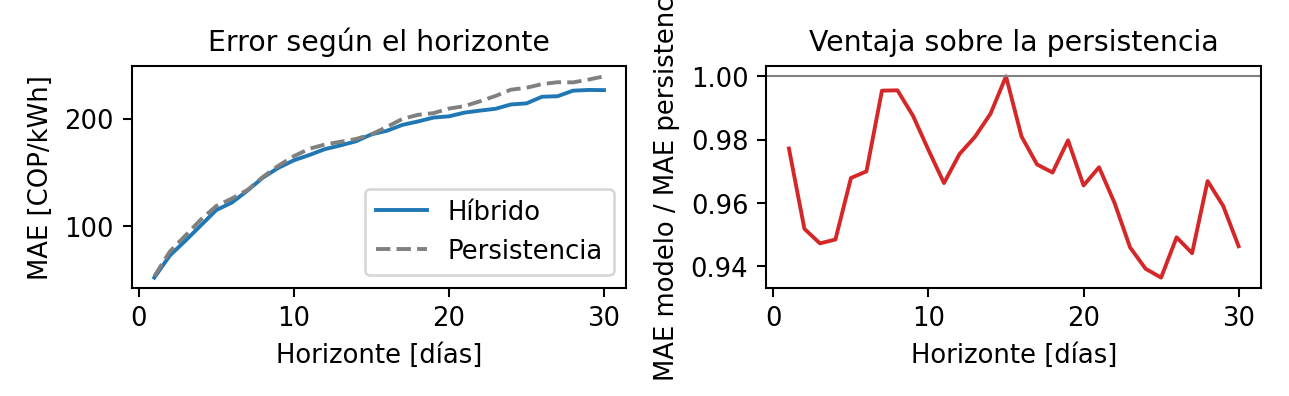


La razón va de 0.977 en h = 1 a 0.946 en h = 30.
Mejor en h = 25 (0.936); peor en h = 15 (1.000).
Horizontes en que no supera a la persistencia: 0 de 30.


In [12]:
# ============================================================
# 8.3 Cómo crece el error con el horizonte
# ============================================================
pers_test = s["precio_hoy"].values[I_PRUEBA]
filas_h = []
for k in range(HORIZONTE):
    real_h = REALES[I_PRUEBA][:, k]
    filas_h.append({"horizonte": k + 1,
                    "MAE_modelo": float(np.abs(real_h - TRAY[:, k]).mean()),
                    "MAE_persistencia": float(np.abs(real_h - pers_test).mean()),
                    "n": len(I_PRUEBA)})
por_horizonte = pd.DataFrame(filas_h)
por_horizonte["razon"] = por_horizonte["MAE_modelo"] / por_horizonte["MAE_persistencia"]
print(por_horizonte.loc[por_horizonte["horizonte"].isin([1, 2, 3, 7, 14, 21, 30])]
      .round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_modelo"], label="Híbrido")
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_persistencia"], ls="--", color="grey",
             label="Persistencia")
axes[0].set_xlabel("Horizonte [días]"); axes[0].set_ylabel("MAE [COP/kWh]"); axes[0].legend()
axes[0].set_title("Error según el horizonte")
axes[1].plot(por_horizonte["horizonte"], por_horizonte["razon"], color="tab:red")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Horizonte [días]"); axes[1].set_ylabel("MAE modelo / MAE persistencia")
axes[1].set_title("Ventaja sobre la persistencia")
a_escala(fig)
plt.tight_layout(); plt.show()

mejor_h = por_horizonte.loc[por_horizonte["razon"].idxmin()]
peor_h = por_horizonte.loc[por_horizonte["razon"].idxmax()]
print(f"\nLa razón va de {por_horizonte['razon'].iloc[0]:.3f} en h = 1 a "
      f"{por_horizonte['razon'].iloc[-1]:.3f} en h = 30.")
print(f"Mejor en h = {int(mejor_h['horizonte'])} ({mejor_h['razon']:.3f}); "
      f"peor en h = {int(peor_h['horizonte'])} ({peor_h['razon']:.3f}).")
print(f"Horizontes en que no supera a la persistencia: "
      f"{int((por_horizonte['razon'] >= 1).sum())} de {HORIZONTE}.")

In [13]:
# ============================================================
# 8.4 Desempeño por régimen ENSO y por año
# ============================================================
oni = s["indice_ONI_publicado"].values[I_PRUEBA]
fase = np.select([oni >= 0.5, oni <= -0.5], ["El Niño", "La Niña"], default="Neutral")
real_prom = REALES[I_PRUEBA].mean(axis=1)

# El año es el del DÍA PRONOSTICADO, no el del origen: es la misma agrupación de los notebooks 5 y
# 6 y la de la tabla del documento. Agrupar por el año del origen da otros recuentos —334 días en
# 2023 en vez de 304— y las cifras dejarían de ser comparables con las de las otras dos familias.
ANIO_OBJ = (origenes[I_PRUEBA] + pd.Timedelta(days=HORIZONTE)).year

cmp = pd.DataFrame({"fase": fase,
                    "anio": ANIO_OBJ,
                    "precio_medio": real_prom,
                    "e_pers": np.abs(real_prom - pers_test),
                    "e_hib": np.abs(real_prom - TRAY.mean(axis=1))})
for clave, orden in (("fase", ["El Niño", "Neutral", "La Niña"]), ("anio", None)):
    g = cmp.groupby(clave).agg(n=("e_hib", "size"), precio_medio=("precio_medio", "mean"),
                               Persistencia=("e_pers", "mean"), Híbrido=("e_hib", "mean"))
    if orden:
        g = g.loc[orden]
    g["ventaja_%"] = 100 * (1 - g["Híbrido"] / g["Persistencia"])
    print(f"\nMAE sobre el promedio del mes, por {clave}:")
    print(g.round(1).to_string())


MAE sobre el promedio del mes, por fase:
           n  precio_medio  Persistencia  Híbrido  ventaja_%
fase                                                        
El Niño  335         599.3         163.3    154.5        5.4
Neutral  666         453.5         149.9    150.2       -0.2
La Niña  154         234.9          88.8     65.5       26.3

MAE sobre el promedio del mes, por anio:
        n  precio_medio  Persistencia  Híbrido  ventaja_%
anio                                                     
2023  304         576.0         163.5    147.3        9.9
2024  366         670.9         213.6    224.2       -5.0
2025  365         254.9          88.1     78.3       11.1
2026  120         210.4          68.3     53.7       21.4


In [14]:
# ============================================================
# 9. La comparación entre las cuatro familias
# ============================================================
p5 = pd.read_csv(os.path.join(PROC, "5_predicciones_sarimax.csv"), parse_dates=["fecha"])
p6 = pd.read_csv(os.path.join(PROC, "6_predicciones_xgboost.csv"), parse_dates=["fecha"])
p7 = pd.read_csv(os.path.join(PROC, "7_predicciones_lstm.csv"), parse_dates=["fecha"])
p8 = pd.read_csv(os.path.join(PROC, "8_predicciones_gru.csv"), parse_dates=["fecha"])
BASE_SARIMAX = "SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema"
# EL XGBOOST DE LA COMPARACION ES EL DE LA TRAYECTORIA, el mismo que publica la tabla de
# errores. El archivo lleva tambien el estimador directo, que da 143,10 en vez de 143,17; leerlo
# aqui hacia que esta tabla y la prueba de Diebold-Mariano describieran otro modelo, y que sus
# diferencias no cuadraran al restarlas de la tabla de errores. El guard de mas abajo lo verifica.
COL_XGB = next(c for c in p6.columns if "trayectoria" in c and "semilla_" not in c)
# De cada notebook de Deep Learning, su configuración elegida, no una de sus semillas sueltas.
COL_LSTM = next(c for c in p7.columns if c.startswith("LSTM") and "semilla" not in c)
COL_GRU = next(c for c in p8.columns if c.startswith("GRU") and "semilla" not in c)

cmp3 = (pd.DataFrame({"fecha": origenes[I_PRUEBA], "real": real_prom,
                      "Persistencia": pers_test, "Híbrido": TRAY.mean(axis=1)})
        .merge(p5[["fecha", BASE_SARIMAX]], on="fecha")
        .merge(p6[["fecha", COL_XGB]], on="fecha")
        .merge(p7[["fecha", COL_LSTM]], on="fecha")
        .merge(p8[["fecha", COL_GRU]], on="fecha")
        .rename(columns={BASE_SARIMAX: "SARIMAX", COL_XGB: "XGBoost",
                         COL_LSTM: "LSTM", COL_GRU: "GRU"}))
assert len(cmp3) == len(I_PRUEBA), f"la comparación perdió filas: {len(cmp3)} de {len(I_PRUEBA)}"
print(f"Se comparan: «{BASE_SARIMAX}», «{COL_XGB}», «{COL_LSTM}» y «{COL_GRU}».")

MODELOS_CMP = ["Persistencia", "SARIMAX", "XGBoost", "LSTM", "GRU", "Híbrido"]
res = pd.DataFrame([dict(modelo=m, **metricas(cmp3["real"], cmp3[m])) for m in MODELOS_CMP])
res["mejora_%"] = 100 * (1 - res["MAE"] / res.loc[0, "MAE"])

# LAS CIFRAS PUBLICADAS NO SE COPIAN A MANO: se leen del consolidado, que es donde las dejó
# `registrar()`. Si un notebook anterior no se ha corrido, la búsqueda falla y lo dice.
# El consolidado guarda dos bloques por configuración —el entrenamiento, en muestra, y la prueba—
# y esta comparación es sobre la PRUEBA: sin el filtro por bloque la misma clave devuelve dos
# filas y la búsqueda es ambigua.
CONS = pd.read_csv("resultados_modelos.csv")


def mae_publicado(notebook, modelo, trozo=""):
    f = CONS[(CONS["notebook"] == notebook) & (CONS["modelo"] == modelo)
             & (CONS["objetivo"] == "promedio_30d") & (CONS["bloque"] == "prueba")
             & CONS["configuracion"].str.contains(trozo, regex=False)]
    assert len(f) == 1, (f"{notebook} / {modelo} / «{trozo}» en la prueba: {len(f)} filas, "
                         f"se esperaba 1")
    return float(f["MAE"].iloc[0])


PUBLICADO = (
    ("Persistencia", mae_publicado("7_LSTM_modelo_base", "Referencia: persistencia (P de hoy)")),
    ("SARIMAX", mae_publicado("5_SARIMAX_modelo_base", "SARIMAX", BASE_SARIMAX)),
    ("XGBoost", mae_publicado("6_XGBoost_modelo_base", "XGBoost", COL_XGB)),
    ("LSTM", mae_publicado("7_LSTM_modelo_base", "LSTM")),
    ("GRU", mae_publicado("8_GRU_modelo_base", "GRU")),
)
for modelo, publicado in PUBLICADO:
    obtenido = float(res.loc[res["modelo"] == modelo, "MAE"].iloc[0])
    assert abs(obtenido - publicado) < 0.02, \
        f"{modelo} da {obtenido:.2f} aquí y {publicado} en su notebook: el montaje no coincide"

print("\nLas cuatro familias y la referencia, sobre el promedio del mes:")
print(res.round(2).to_string(index=False))
print("\nLos cinco modelos anteriores reproducen las cifras que dejaron en el consolidado:")
print("  " + "  |  ".join(f"{m} {v:.2f}".replace(".", ",") for m, v in PUBLICADO))
print("La partición, el embargo y los 1.155 orígenes son los mismos. El montaje es el mismo.")

cmp3["fase"] = fase
cmp3["anio"] = ANIO_OBJ            # el año del día pronosticado, como en los notebooks 5, 6, 7 y 8
for clave, orden in (("fase", ["El Niño", "Neutral", "La Niña"]), ("anio", None)):
    g = pd.DataFrame({m: cmp3.groupby(clave).apply(
        lambda x, m=m: np.abs(x["real"] - x[m]).mean(), include_groups=False)
        for m in MODELOS_CMP})
    if orden:
        g = g.loc[orden]
    print(f"\nMAE por {clave}:")
    print(g.round(1).to_string())
    otros = ["SARIMAX", "XGBoost", "LSTM", "GRU"]
    gana = int((g["Híbrido"] < g[otros].min(axis=1)).sum())
    print(f"  {clave}s en que el híbrido supera a los cuatro anteriores: {gana} de {len(g)}")
    mejor = g[MODELOS_CMP[1:]].idxmin(axis=1)
    print("  el mejor en cada uno: " + ", ".join(f"{k}: {v}" for k, v in mejor.items()))
    # LA MEJORA RELATIVA, no solo el MAE: el error absoluto de un segmento lo fija sobre todo
    # su nivel de precio, y comparar familias entre regímenes con la cifra absoluta confunde
    # el nivel con el acierto. El porcentaje se calcula sobre los valores exactos, que no es
    # lo mismo que dividir los redondeados de la tabla de arriba.
    mejora = 100 * (1 - g[MODELOS_CMP[1:]].div(g["Persistencia"], axis=0))
    print(f"  mejora sobre la persistencia por {clave}, en %:")
    print("  " + mejora.round(1).to_string().replace("\n", "\n  "))
    for m in MODELOS_CMP[1:]:
        detras = [str(k) for k in g.index if g.loc[k, m] >= g.loc[k, "Persistencia"]]
        print(f"  {m} no supera a la persistencia en: "
              + (", ".join(detras) if detras else "ningún corte"))
# LA LECTURA ECONÓMICA. Un error absoluto no se interpreta solo: 132 COP/kWh es mucho o
# poco según el precio que estima. Se imprime el nivel del periodo y el error en relación
# con él, que es lo que permite decir qué significa la ventaja para quien compra o vende.
nivel = float(cmp3["real"].mean())
print(f"\nPrecio medio observado en los {len(cmp3)} orígenes de prueba: "
      f"{nivel:.1f} COP/kWh")
eco = res[["modelo", "MAE"]].copy()
eco["MAE_%_precio"] = 100 * eco["MAE"] / nivel
eco["ventaja_COP"] = float(res.loc[0, "MAE"]) - eco["MAE"]
eco["ventaja_%_precio"] = 100 * eco["ventaja_COP"] / nivel
print(eco.round(2).to_string(index=False))
print("  La ventaja se mide contra la persistencia, que es la referencia que el agente\n"
      "  ya tiene sin modelo alguno: comprometer al precio de hoy.")

Se comparan: «SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema», «XGBoost profundidad 1, 200 árboles, mcw 100, tasa 0,02 (trayectoria, 5 semillas)», «LSTM 32, 3 épocas» y «GRU 32, 15 épocas».

Las cuatro familias y la referencia, sobre el promedio del mes:
      modelo    MAE   RMSE  SMAPE  mejora_%
Persistencia 145.66 232.21  30.54      0.00
     SARIMAX 136.70 206.31  28.66      6.15
     XGBoost 143.17 218.09  30.40      1.71
        LSTM 144.83 214.62  31.09      0.57
         GRU 132.47 209.20  26.75      9.06
     Híbrido 140.17 215.80  28.86      3.77

Los cinco modelos anteriores reproducen las cifras que dejaron en el consolidado:
  Persistencia 145,66  |  SARIMAX 136,70  |  XGBoost 143,17  |  LSTM 144,83  |  GRU 132,47
La partición, el embargo y los 1.155 orígenes son los mismos. El montaje es el mismo.

MAE por fase:
         Persistencia  SARIMAX  XGBoost   LSTM    GRU  Híbrido
fase                                                          
El Niño         163.3    152.5 

In [15]:
# ============================================================
# 9.1 Las métricas del entrenamiento, junto a las de la prueba
# ============================================================
# QUÉ FALTABA. Hasta aquí el notebook informa del error sobre la prueba y, en la rejilla, de la
# razón frente a la persistencia en los cinco pliegues de validación. Falta la otra mitad de la
# pregunta: cuánto acierta el modelo sobre los datos con los que se ajustó. Sin esa cifra el
# control del sobreajuste se puede argumentar —parar a tiempo— pero no medir.
#
# CÓMO SE MIDE, Y POR QUÉ ASÍ. Con el mismo rasero que la prueba: la configuración elegida se
# ajusta con el bloque de entrenamiento completo —el mismo ajuste que produce el primer
# pronóstico de la prueba— y se le piden las trayectorias de treinta días de ESOS MISMOS orígenes,
# los que el ajuste vio. NO se usa la pérdida de entrenamiento de Keras: mide el error del cambio
# logarítmico a la escala de la red, no el del precio a treinta días, y ponerla junto al MAE de la
# prueba diría que el modelo empeora un orden de magnitud al salir de la muestra cuando la mayor
# parte de esa diferencia sería solo el cambio de unidad.
from _entrenamiento import tabla_brecha, registrar_brecha, leer_brecha

I_ENTREN = indices_ajuste(ORIGENES_PRUEBA[0])
assert origenes[I_ENTREN].max() <= FIN_ENTRENAMIENTO, "el bloque en muestra entra en el embargo"

t0 = time.time()
TRAY_ENTREN = np.mean([ajustar_predecir(PARAMETROS, I_ENTREN, I_ENTREN, sm, EPOCAS)[0]
                       for sm in SEMILLAS], axis=0)
print(f"En muestra: {len(I_ENTREN)} origenes de {origenes[I_ENTREN].min().date()} a "
      f"{origenes[I_ENTREN].max().date()}, promediados sobre {len(SEMILLAS)} semillas "
      f"({time.time() - t0:.0f} s)")

PERS_ENTREN = np.repeat(s["precio_hoy"].values[I_ENTREN][:, None], HORIZONTE, axis=1)
BRECHA = tabla_brecha({"entrenamiento": (TRAY_ENTREN, REALES[I_ENTREN], PERS_ENTREN),
                       "prueba": (TRAY, REALES[I_PRUEBA], PERSIST)})
print()
print(BRECHA.round(3).to_string(index=False))
print()
print(leer_brecha(BRECHA))

registrar_brecha(BRECHA, notebook="9_Hibrido_BiLSTM_atencion_modelo_base", familia="Deep Learning", modelo="Híbrido",
                 configuracion=f"{MEJOR} ({len(SEMILLAS)} semillas)",
                 particion="65/15/20 por fecha", embargo_dias=dias_embargo,
                 reajuste_dias=None, verbose=True)

BRECHA.to_csv(os.path.join(PROC, "9_brecha_entrenamiento_prueba.csv"), index=False)
print(f"\n  [datasets/procesado] 9_brecha_entrenamiento_prueba.csv")

# ------------------------------------------------------------
# El error de CADA ventana de treinta días
# ------------------------------------------------------------
# La tabla de arriba resume cada bloque en una cifra, y una cifra no dice si el modelo acierta
# de forma pareja o alterna tramos buenos y malos. Se guarda el error de cada pronóstico por
# separado, con su persistencia, para poder ver cómo evoluciona a lo largo del periodo.
from _entrenamiento import error_por_origen

DETALLE = error_por_origen({"entrenamiento": (TRAY_ENTREN, REALES[I_ENTREN], PERS_ENTREN, origenes[I_ENTREN]),
                            "prueba": (TRAY, REALES[I_PRUEBA], PERSIST, origenes[I_PRUEBA])})
DETALLE.to_csv(os.path.join(PROC, "9_error_por_origen.csv"), index=False)
print(f"\n  [datasets/procesado] 9_error_por_origen.csv  "
      f"({len(DETALLE)} orígenes: "
      f"{(DETALLE['bloque'] == 'entrenamiento').sum()} en muestra y "
      f"{(DETALLE['bloque'] == 'prueba').sum()} de prueba)")
print(DETALLE.groupby("bloque")[["MAE", "MAE_persistencia", "razon"]].median().round(3)
      .to_string())

En muestra: 4568 origenes de 2010-06-30 a 2022-12-31, promediados sobre 5 semillas (84 s)

       bloque  n_origenes     objetivo     MAE    RMSE  SMAPE  MAE_persistencia  razon
entrenamiento        4568    pares_30d  43.778  93.193 20.880            52.768  0.830
       prueba        1155    pares_30d 172.301 278.204 35.962           178.369  0.966
entrenamiento        4568 promedio_30d  35.056  71.044 16.636            45.461  0.771
       prueba        1155 promedio_30d 140.166 215.798 28.861           145.662  0.962
entrenamiento        4568       dia_30  55.309 114.031 26.036            71.760  0.771
       prueba        1155       dia_30 226.445 340.491 47.055           239.273  0.946

El MAE pasa de 35.06 en el entrenamiento a 140.17 en la prueba, 4.00 veces mayor. La
persistencia pasa de 45.46 a 145.66 sobre los mismos orígenes, 3.20 veces, y la razón
frente a ella pasa de 0.771 a 0.962.
Descontado lo que sube la persistencia, queda un deterioro de 25 % en la razón:
hay brecha,


  [datasets/procesado] 9_error_por_origen.csv  (5723 orígenes: 4568 en muestra y 1155 de prueba)
                   MAE  MAE_persistencia  razon
bloque                                         
entrenamiento   26.316            30.763  0.891
prueba         114.640           118.754  0.959


Curva de aprendizaje de la configuracion elegida, promediada sobre los 5 pliegues (279 s):

 epocas  MAE_ajuste  MAE_validacion  razon_ajuste  razon_validacion
      3      33.989          49.095         0.918             0.945
      5      31.737          48.016         0.860             0.927
     10      27.099          48.945         0.726             0.954
     15      23.186          52.286         0.616             1.039
     30      17.098          55.184         0.452             1.112
     60      14.252          57.874         0.373             1.164

La razon frente a la persistencia es minima en el AJUSTE a las 60 epocas y en la VALIDACION a las 5.
  A partir de las 5 la red sigue mejorando sobre lo que ya vio y empeora sobre lo que no:
  eso es sobreajuste, y es lo que fija el numero de epocas en 5.


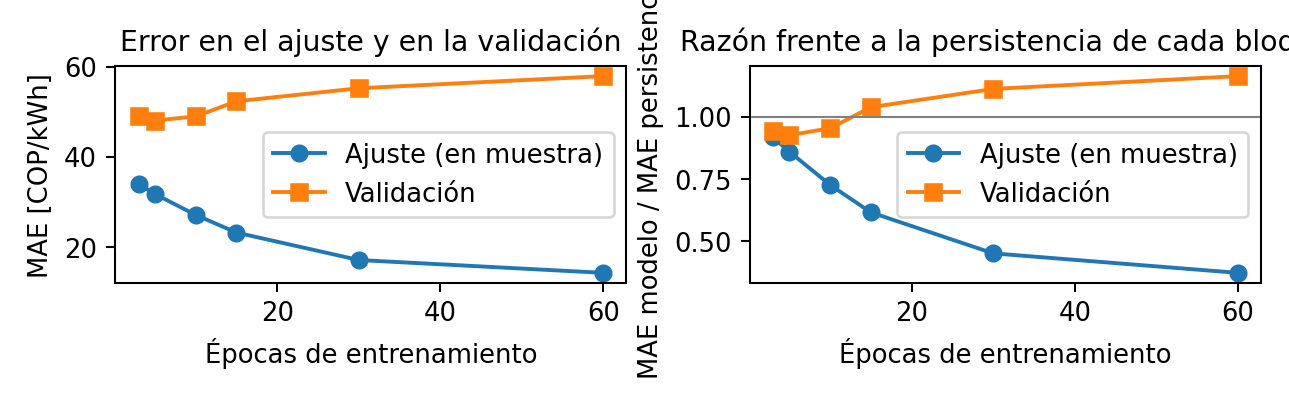


  [datasets/procesado] 9_curva_aprendizaje.csv


In [16]:
# ============================================================
# 9.2 La curva de aprendizaje: ajuste contra validación, época a época
# ============================================================
# Es la evidencia directa del sobreajuste de esta familia, y la que la rejilla solo podía
# insinuar. Allí se mide la razón de VALIDACIÓN en seis cortes de épocas; aquí se mide, en los
# mismos cortes y con la misma red, también el error sobre el conjunto de AJUSTE. Si la curva de
# ajuste baja mientras la de validación sube, lo que la red gana entrenando más es memoria.
#
# Se entrena UNA vez por pliegue hasta el último corte y se evalúa al pasar por cada uno: entrenar
# una red por corte repetiría el trabajo seis veces para obtener lo mismo.
def curva_ajuste_validacion(params, fin_ajuste, v_ini, v_fin, semilla=42):
    """MAE del promedio del mes sobre el ajuste y sobre la validación, en cada corte de épocas."""
    i_val = np.where((origenes >= pd.Timestamp(v_ini)) & (origenes <= pd.Timestamp(v_fin)))[0]
    i_aj = np.where((s["fecha_objetivo"] <= pd.Timestamp(fin_ajuste)).values & ~EN_EMBARGO)[0]
    assert origenes[i_aj].max() <= pd.Timestamp(fin_ajuste), "la purga no cierra antes del pliegue"
    X_aj, X_ev = escalar(i_aj, i_val)
    modelo = construir_modelo(semilla=semilla, **params)

    def mae(i, X):
        z = modelo.predict([X, ESTATICAS[i].astype("float32")], verbose=0)
        pred = s["precio_hoy"].values[i][:, None] * np.exp(z)
        return float(np.abs(REALES[i].mean(axis=1) - pred.mean(axis=1)).mean())

    per = {"ajuste": float(np.abs(REALES[i_aj].mean(axis=1)
                                  - s["precio_hoy"].values[i_aj]).mean()),
           "validacion": float(np.abs(REALES[i_val].mean(axis=1)
                                      - s["precio_hoy"].values[i_val]).mean())}
    filas, hechas = [], 0
    for corte in CORTES:
        modelo.fit([X_aj, ESTATICAS[i_aj].astype("float32")], Z[i_aj].astype("float32"),
                   epochs=corte - hechas, batch_size=64, verbose=0, shuffle=True)
        hechas = corte
        m_aj, m_val = mae(i_aj, X_aj), mae(i_val, X_ev)
        filas.append({"epocas": corte, "MAE_ajuste": m_aj, "MAE_validacion": m_val,
                      "razon_ajuste": m_aj / per["ajuste"],
                      "razon_validacion": m_val / per["validacion"]})
    return pd.DataFrame(filas)


t0 = time.time()
curvas_ap = [curva_ajuste_validacion(PARAMETROS, *pl) for pl in PLIEGUES]
CURVA = (pd.concat(curvas_ap).groupby("epocas").mean().reset_index())
print(f"Curva de aprendizaje de la configuracion elegida, promediada sobre los "
      f"{len(PLIEGUES)} pliegues ({time.time() - t0:.0f} s):\n")
print(CURVA.round(3).to_string(index=False))

# SE LEE LA RAZÓN, NO EL MAE CRUDO. Los cinco pliegues caen en tramos de distinto nivel de precio
# y promediar sus MAE pondera los caros; la razón frente a la persistencia de cada pliegue es la
# cantidad con la que se eligió la configuración. Si las dos no apuntan al mismo corte, se dice.
_c = CURVA.set_index("epocas")
_opt_aj = int(_c["razon_ajuste"].idxmin())
_opt_val = int(_c["razon_validacion"].idxmin())
_opt_mae = int(_c["MAE_validacion"].idxmin())
print(f"\nLa razon frente a la persistencia es minima en el AJUSTE a las {_opt_aj} epocas "
      f"y en la VALIDACION a las {_opt_val}.")
if _opt_mae != _opt_val:
    print(f"  El MAE crudo de validacion, en cambio, es minimo a las {_opt_mae}: entre los dos "
          f"cortes hay\n  "
          f"{abs(_c.loc[_opt_mae, 'MAE_validacion'] - _c.loc[_opt_val, 'MAE_validacion']):.2f}"
          f" COP/kWh de diferencia, y no coinciden porque cada pliegue\n  tiene su propio nivel "
          f"de persistencia.")
if _opt_aj > _opt_val:
    print(f"  A partir de las {_opt_val} la red sigue mejorando sobre lo que ya vio y empeora "
          f"sobre lo que no:\n  eso es sobreajuste, y es lo que fija el numero de epocas en "
          f"{EPOCAS}.")
else:
    print("  Las dos curvas tienen su mínimo en el mismo corte: la rejilla no separa aquí el "
          "ajuste\n  de la generalización, y el número de épocas no se puede justificar por esta "
          "via.")

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].plot(CURVA["epocas"], CURVA["MAE_ajuste"], marker="o", label="Ajuste (en muestra)")
axes[0].plot(CURVA["epocas"], CURVA["MAE_validacion"], marker="s", label="Validación")
axes[0].set_xlabel("Épocas de entrenamiento"); axes[0].set_ylabel("MAE [COP/kWh]")
axes[0].set_title("Error en el ajuste y en la validación"); axes[0].legend()
axes[1].plot(CURVA["epocas"], CURVA["razon_ajuste"], marker="o", label="Ajuste (en muestra)")
axes[1].plot(CURVA["epocas"], CURVA["razon_validacion"], marker="s", label="Validación")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Épocas de entrenamiento")
axes[1].set_ylabel("MAE modelo / MAE persistencia")
axes[1].set_title("Razón frente a la persistencia de cada bloque"); axes[1].legend()
a_escala(fig)
plt.tight_layout()
plt.show()

CURVA.to_csv(os.path.join(PROC, "9_curva_aprendizaje.csv"), index=False)
print(f"\n  [datasets/procesado] 9_curva_aprendizaje.csv")


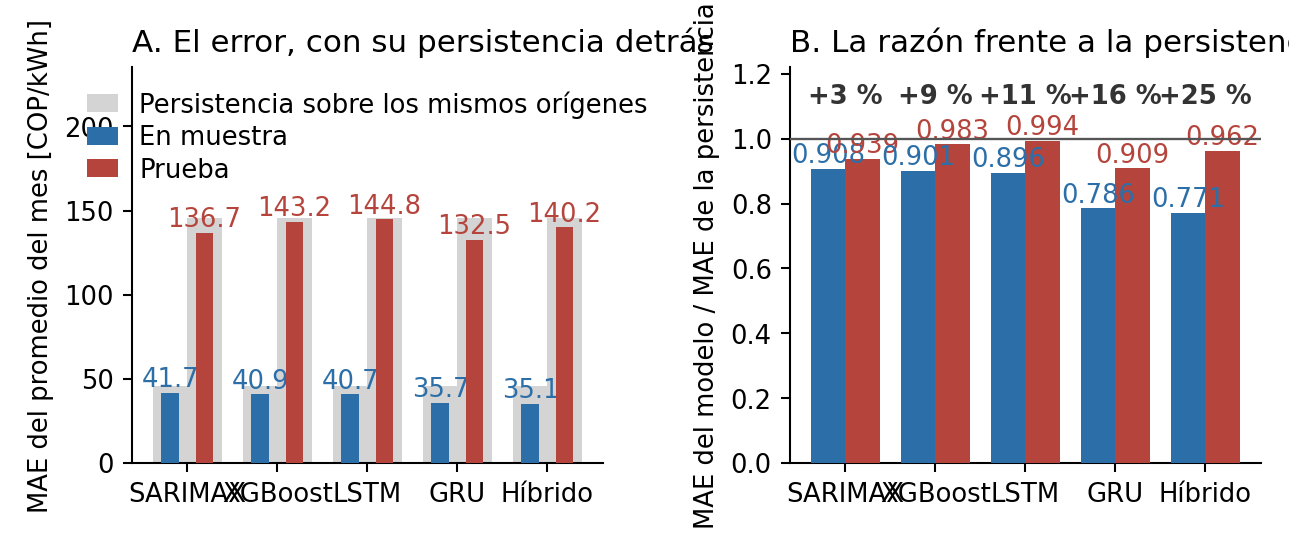

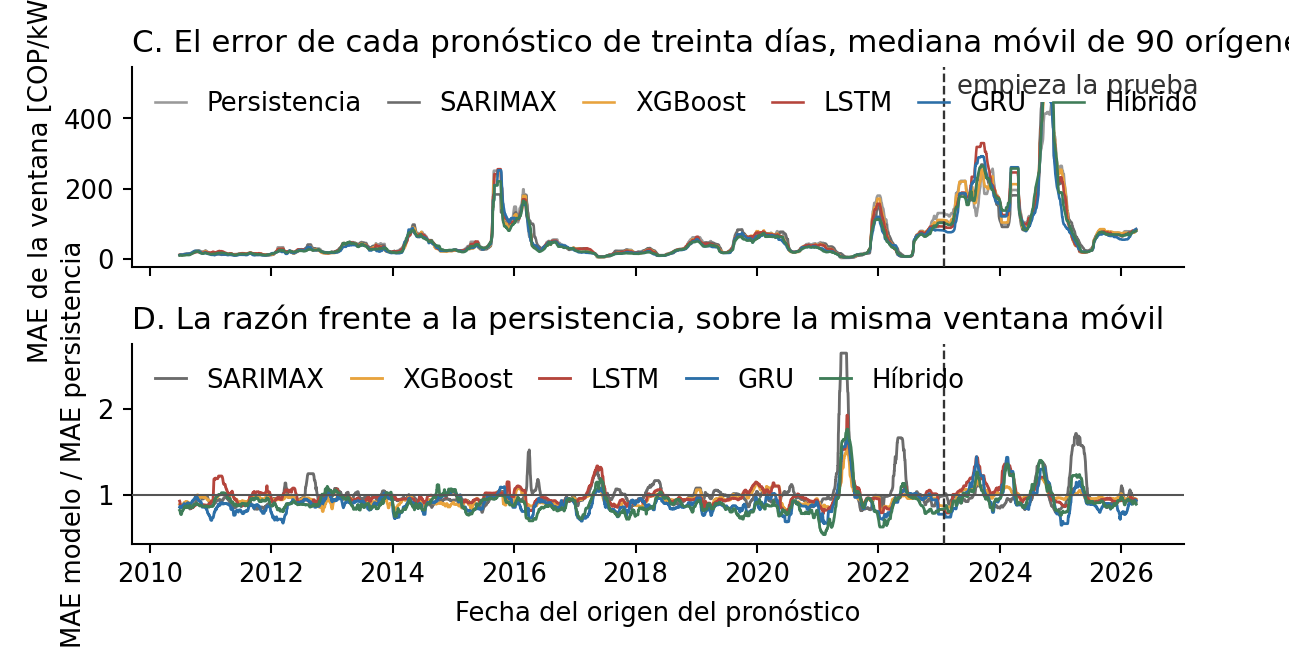

Orígenes por bloque: 4568 en muestra y 1155 de prueba; la prueba empieza el 2023-02-01.

Sobre la PRUEBA, origen a origen (lo que el promedio esconde):
         gana_%  razon_mediana  movil_min  movil_max  trim_min  trim_max  trim_factor
modelo                                                                               
SARIMAX    56.6          0.956       0.80       1.71     31.26    384.82         12.3
XGBoost    50.9          0.997       0.82       1.19     18.25    418.88         23.0
LSTM       51.4          0.991       0.59       1.44     18.80    403.99         21.5
GRU        57.7          0.932       0.49       1.44     20.55    373.22         18.2
Híbrido    55.8          0.959       0.76       1.40     19.65    450.97         23.0

Razón mediana por bloque y modelo:
               SARIMAX  XGBoost   LSTM    GRU  Híbrido
bloque                                                
entrenamiento    0.961    0.943  0.962  0.893    0.891
prueba           0.956    0.997  0.991  0.932

In [17]:
# ============================================================
# 9.3 — El entrenamiento y la prueba, de un vistazo
# ============================================================
# QUÉ AÑADEN A LA TABLA DE LA BRECHA. La tabla resume cada bloque en una cifra. Estas dos figuras
# responden lo que la cifra no: la primera, si la distancia entre los dos bloques es sobreajuste
# o dificultad del periodo; la segunda, si el acierto es parejo o alterna tramos.
#
# POR QUÉ LA PRIMERA LLEVA LA PERSISTENCIA DETRÁS. El MAE se multiplica por entre 3,3 y 4,0 del
# entrenamiento a la prueba, y eso solo parece sobreajuste hasta que se mira que la persistencia
# se multiplica por 3,2 sobre esos mismos orígenes. Poner la referencia al lado de cada barra
# evita la lectura falsa; el panel derecho da la razón, que es la cantidad comparable.
#
# POR QUÉ LA SEGUNDA NO SE LEE COMO DESEMPEÑO EN TODO SU ANCHO. En el tramo en muestra el modelo
# YA VIO esos días: su error bajo ahí es memoria, no pronóstico. Las dos mitades están juntas
# porque su contraste es el asunto, no porque sean la misma medida.
import matplotlib.dates as mdates

FAMILIAS_FIG = [("5", "SARIMAX", "#6b6b6b"), ("6", "XGBoost", "#e8a33d"),
                ("7", "LSTM", "#b5453c"), ("8", "GRU", "#2c6fa8"),
                ("9", "Híbrido", "#3f7d58")]
OBJ_FIG = "promedio_30d"

_br = {}
for _n, _m, _c in FAMILIAS_FIG:
    _d = pd.read_csv(os.path.join(PROC, f"{_n}_brecha_entrenamiento_prueba.csv"))
    _br[_m] = _d[_d["objetivo"] == OBJ_FIG].set_index("bloque")

_x = np.arange(len(FAMILIAS_FIG))
_an = 0.38
fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 5.4)))

ax = axes[0]
for _k, (_pos, _bl, _col, _etq) in enumerate([(-1, "entrenamiento", "#2c6fa8", "En muestra"),
                                              (1, "prueba", "#b5453c", "Prueba")]):
    _per = [_br[m].loc[_bl, "MAE_persistencia"] for _, m, _ in FAMILIAS_FIG]
    _mae = [_br[m].loc[_bl, "MAE"] for _, m, _ in FAMILIAS_FIG]
    ax.bar(_x + _pos * _an / 2, _per, _an, color="#d4d4d4", zorder=2,
           label="Persistencia sobre los mismos orígenes" if _k == 0 else None)
    ax.bar(_x + _pos * _an / 2, _mae, _an * 0.52, color=_col, zorder=3, label=_etq)
    for _i, _v in enumerate(_mae):
        ax.annotate(f"{_v:.1f}", (_i + _pos * _an / 2, _v), ha="center", va="bottom",
                    fontsize=10, color=_col)
ax.set_xticks(_x); ax.set_xticklabels([m for _, m, _ in FAMILIAS_FIG])
ax.set_ylabel("MAE del promedio del mes [COP/kWh]")
ax.set_title("A. El error, con su persistencia detrás", loc="left")
ax.legend(frameon=False, loc="upper center", handlelength=1.2, labelspacing=0.25)
ax.set_ylim(0, 235)
for _l in ("top", "right"):
    ax.spines[_l].set_visible(False)

ax = axes[1]
_r_en = [_br[m].loc["entrenamiento", "razon"] for _, m, _ in FAMILIAS_FIG]
_r_pr = [_br[m].loc["prueba", "razon"] for _, m, _ in FAMILIAS_FIG]
# sin `label`: los colores son los del panel A y su leyenda ya los nombra
ax.bar(_x - _an / 2, _r_en, _an, color="#2c6fa8", zorder=3)
ax.bar(_x + _an / 2, _r_pr, _an, color="#b5453c", zorder=3)
ax.axhline(1.0, color="#555", lw=0.9, zorder=4)
for _i, (_a, _b) in enumerate(zip(_r_en, _r_pr)):
    ax.annotate(f"{_a:.3f}", (_i - _an / 2, _a), ha="center", va="bottom", fontsize=10,
                color="#2c6fa8")
    ax.annotate(f"{_b:.3f}", (_i + _an / 2, _b), ha="center", va="bottom", fontsize=10,
                color="#b5453c")
    ax.annotate(f"+{(_b / _a - 1) * 100:.0f} %", (_i, 1.09), ha="center", va="bottom",
                fontsize=10, color="#333", weight="bold")
ax.set_xticks(_x); ax.set_xticklabels([m for _, m, _ in FAMILIAS_FIG])
ax.set_ylabel("MAE del modelo / MAE de la persistencia")
ax.set_title("B. La razón frente a la persistencia", loc="left")
ax.set_ylim(0, 1.22)
for _l in ("top", "right"):
    ax.spines[_l].set_visible(False)
a_escala(fig)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# La evolución pronóstico a pronóstico
# ------------------------------------------------------------
_det = {}
for _n, _m, _c in FAMILIAS_FIG:
    _det[_m] = pd.read_csv(os.path.join(PROC, f"{_n}_error_por_origen.csv"),
                           parse_dates=["fecha_origen"])
_pers = _det["GRU"].set_index("fecha_origen")["MAE_persistencia"]
_frontera = _det["GRU"].loc[_det["GRU"]["bloque"] == "prueba", "fecha_origen"].min()

fig, axes = plt.subplots(2, 1, figsize=(ANCHO_PAGINA, alto_pagina(13, 6.6)), sharex=True)
_VENTANA = 90          # orígenes de la mediana móvil; suaviza sin borrar los episodios

ax = axes[0]
ax.plot(_pers.index, _pers.rolling(_VENTANA, center=True, min_periods=20).median(),
        color="#999", lw=1.0, label="Persistencia", zorder=2)
for _n, _m, _c in FAMILIAS_FIG:
    _s = _det[_m].set_index("fecha_origen")["MAE"]
    ax.plot(_s.index, _s.rolling(_VENTANA, center=True, min_periods=20).median(),
            color=_c, lw=1.0, label=_m, zorder=3)
ax.axvline(_frontera, color="#333", lw=0.9, ls="--", zorder=5)
ax.annotate("empieza la prueba", (_frontera, ax.get_ylim()[1] * 0.97), xytext=(5, 0),
            textcoords="offset points", fontsize=10, color="#333", va="top",
            bbox=dict(facecolor="white", edgecolor="none", pad=1.0))
ax.set_ylabel("MAE de la ventana [COP/kWh]")
ax.set_title(f"C. El error de cada pronóstico de treinta días, mediana móvil de {_VENTANA} "
             f"orígenes", loc="left")
ax.legend(frameon=False, ncol=6, loc="upper left", handlelength=1.2, columnspacing=1.0)
for _l in ("top", "right"):
    ax.spines[_l].set_visible(False)

ax = axes[1]
ax.axhline(1.0, color="#555", lw=0.8, zorder=4)
for _n, _m, _c in FAMILIAS_FIG:
    _s = _det[_m].set_index("fecha_origen")["razon"]
    ax.plot(_s.index, _s.rolling(_VENTANA, center=True, min_periods=20).median(),
            color=_c, lw=1.1, label=_m, zorder=3)
ax.axvline(_frontera, color="#333", lw=0.9, ls="--", zorder=5)
ax.set_ylabel("MAE modelo / MAE persistencia")
ax.set_xlabel("Fecha del origen del pronóstico")
ax.set_title("D. La razón frente a la persistencia, sobre la misma ventana móvil", loc="left")
ax.legend(frameon=False, ncol=5, loc="upper left", handlelength=1.2, columnspacing=1.0)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for _l in ("top", "right"):
    ax.spines[_l].set_visible(False)
a_escala(fig)
plt.tight_layout()
plt.show()

print(f"Orígenes por bloque: "
      f"{(_det['GRU']['bloque'] == 'entrenamiento').sum()} en muestra y "
      f"{(_det['GRU']['bloque'] == 'prueba').sum()} de prueba; la prueba empieza el "
      f"{_frontera.date()}.")
# Las tres lecturas que la figura enseña y que el promedio esconde. Se imprimen aquí porque
# son las que el documento cita, y una cifra que el cuaderno no escribe no puede ir al texto.
_res = []
for _n, _m, _c in FAMILIAS_FIG:
    _p = _det[_m][_det[_m]["bloque"] == "prueba"].set_index("fecha_origen")
    _mv = _p["razon"].rolling(_VENTANA, center=True, min_periods=20).median()
    _tr = _p["MAE"].resample("QE").median()
    _res.append({"modelo": _m, "gana_%": 100 * (_p["razon"] < 1).mean(),
                 "razon_mediana": _p["razon"].median(),
                 "movil_min": _mv.min(), "movil_max": _mv.max(),
                 "trim_min": _tr.min(), "trim_max": _tr.max(),
                 "trim_factor": _tr.max() / _tr.min()})
print()
print("Sobre la PRUEBA, origen a origen (lo que el promedio esconde):")
# Cada columna con los decimales con que se lee: un porcentaje no se cita con tres y una razon
# no se distingue con uno. El documento cita exactamente lo que esta tabla imprime.
_t = pd.DataFrame(_res).set_index("modelo")
for _cols, _d in ((["gana_%", "trim_factor"], 1), (["razon_mediana"], 3),
                  (["movil_min", "movil_max"], 2), (["trim_min", "trim_max"], 2)):
    _t[_cols] = _t[_cols].round(_d)
print(_t.to_string())
print()
print("Razón mediana por bloque y modelo:")
print(pd.DataFrame({_m: _d.groupby("bloque")["razon"].median()
                    for _, _m, _ in FAMILIAS_FIG for _d in [_det[_m]]}).round(3).to_string())

In [18]:
# ============================================================
# 9.4 ¿Son distinguibles esas diferencias? La prueba de Diebold-Mariano
# ============================================================
# QUÉ RESPONDE, Y QUÉ NO. La tabla de la sección 9 ordena las cinco configuraciones por su MAE,
# pero un orden no dice si la distancia entre dos de ellas supera al ruido de la muestra. La prueba
# de Diebold y Mariano (1995) contrasta exactamente eso: toma la diferencia de pérdida origen a
# origen entre dos pronósticos y pregunta si su media se distingue de cero. No dice cuál es mejor
# —eso ya lo dice el MAE—, sino si estos 1.155 orígenes bastan para afirmarlo.
#
# POR QUÉ NO SIRVE LA VERSIÓN DIRECTA, y es el punto que decide el resultado. Dos orígenes
# consecutivos comparten VENTANA-1 de sus días objetivo, de modo que sus pérdidas están
# correlacionadas por construcción: los 1.155 valores no son 1.155 observaciones independientes. El
# estadístico que divide por la desviación muestral simple trata ese solapamiento como información
# nueva y multiplica la evidencia. Se calcula aquí al lado, en la columna `DM_sin_corregir`, solo
# para mostrar cuánto exagera; no es el que se lee.
#
# LA CORRECCIÓN es la habitual para pronósticos a varios pasos: varianza de largo plazo con núcleo
# de Bartlett y HORIZONTE-1 rezagos —el último en que dos ventanas todavía se solapan—, más el
# ajuste de muestra pequeña de Harvey, Leybourne y Newbold (1997), contrastado contra una t con
# n-1 grados de libertad en vez de una normal.
#
# LAS QUINCE COMPARACIONES. Seis series dan quince pares, y contrastar quince hipótesis al 5 %
# produce algún falso positivo con probabilidad cercana a la mitad. Se añade por eso el p-valor
# corregido por el método de Holm, que es el que hay que leer para una conclusión conjunta.
#
# LA PÉRDIDA ES EL ERROR ABSOLUTO DEL PROMEDIO DEL MES, la misma lectura que publica la tabla de
# arriba y la única que el documento reporta. La prueba se hace sobre la medida que se compara, no
# sobre otra.
from itertools import combinations
from scipy import stats

REZAGOS_DM = HORIZONTE - 1          # hasta aquí llega el solapamiento entre dos ventanas
PERDIDA = {m: np.abs(cmp3["real"].to_numpy() - cmp3[m].to_numpy()) for m in MODELOS_CMP}
N_DM = len(cmp3)
for m, p in PERDIDA.items():
    esperado = float(res.loc[res["modelo"] == m, "MAE"].iloc[0])
    assert abs(p.mean() - esperado) < 1e-6, f"la pérdida de {m} no da su MAE: {p.mean():.4f}"


def varianza_larga(d, rezagos):
    """Varianza de la media de `d` con núcleo de Bartlett. Devuelve también la autocovarianza 0."""
    x = d - d.mean()
    g = [float(x @ x) / len(d)]
    for k in range(1, rezagos + 1):
        g.append(float(x[k:] @ x[:-k]) / len(d))
    larga = g[0] + 2.0 * sum((1.0 - k / (rezagos + 1.0)) * g[k] for k in range(1, rezagos + 1))
    assert larga > 0, "la varianza de largo plazo sale no positiva: el núcleo no está pesando bien"
    return larga / len(d), g[0] / len(d)


filas_dm = []
for a, b in combinations(MODELOS_CMP, 2):
    d = PERDIDA[a] - PERDIDA[b]
    var, var_simple = varianza_larga(d, REZAGOS_DM)
    bruto = d.mean() / np.sqrt(var)
    # Harvey, Leybourne y Newbold (1997), ecuación (9) para un pronóstico a h pasos
    factor = np.sqrt((N_DM + 1.0 - 2.0 * HORIZONTE
                      + HORIZONTE * (HORIZONTE - 1.0) / N_DM) / N_DM)
    est = bruto * factor
    filas_dm.append({
        "A": a, "B": b,
        "dif_MAE": d.mean(),
        "DM": est,
        "p": 2.0 * stats.t.sf(abs(est), df=N_DM - 1),
        "DM_sin_corregir": d.mean() / np.sqrt(var_simple),
        "p_sin_corregir": 2.0 * stats.norm.sf(abs(d.mean() / np.sqrt(var_simple))),
        # cuántas observaciones independientes equivalen a los 1.155 orígenes solapados
        "n_efectivo": N_DM * var_simple / var,
    })

dm = pd.DataFrame(filas_dm).sort_values("p").reset_index(drop=True)
# Holm: el p-valor i-ésimo en orden creciente se multiplica por (m-i+1) y la serie se hace monótona
m_dm = len(dm)
dm["p_Holm"] = np.minimum(
    np.maximum.accumulate(dm["p"].to_numpy() * np.arange(m_dm, 0, -1)), 1.0)
assert dm["p_Holm"].is_monotonic_increasing, "el ajuste de Holm no quedó monótono"
assert (dm["p_Holm"] >= dm["p"] - 1e-12).all(), "Holm no puede rebajar un p-valor"

# LA PRECISIÓN DE LA IMPRESIÓN ES LA QUE SE REPORTA, no una más fina: dos decimales para las
# diferencias y el estadístico, tres para los p-valores. Un cuadro impreso con cuatro decimales
# obligaría a redondear al llevarlo a un informe, y entonces la cifra del informe no aparecería en
# ninguna salida de este cuaderno. El archivo guardado conserva la precisión completa.
FORMATO = {"dif_MAE": "{:.2f}".format, "DM": "{:.2f}".format, "p": "{:.3f}".format,
           "DM_sin_corregir": "{:.2f}".format, "p_sin_corregir": "{:.3f}".format,
           "n_efectivo": "{:.0f}".format, "p_Holm": "{:.3f}".format}
print(f"Diebold-Mariano sobre el promedio del mes: {N_DM} orígenes, {m_dm} pares, "
      f"{REZAGOS_DM} rezagos de Bartlett")
print(dm.to_string(index=False, formatters=FORMATO))

sig = dm[dm["p"] < 0.05]
print(f"\nPares con p < 0,05 antes de corregir por multiplicidad: {len(sig)} de {m_dm}")
print(f"Pares con p < 0,05 tras el ajuste de Holm: {int((dm['p_Holm'] < 0.05).sum())} de {m_dm}")
print(f"El p-valor más pequeño es {dm['p'].min():.3f} ({dm.loc[0, 'A']} frente a "
      f"{dm.loc[0, 'B']}, diferencia de {abs(dm.loc[0, 'dif_MAE']):.2f} COP/kWh).")
print(f"\nSi el solapamiento se ignorara, los pares con p < 0,05 serían "
      f"{int((dm['p_sin_corregir'] < 0.05).sum())} de {m_dm}: el estadístico sin corregir es de "
      f"{(dm['DM_sin_corregir'] / dm['DM']).abs().min():.1f} a "
      f"{(dm['DM_sin_corregir'] / dm['DM']).abs().max():.1f} veces el corregido.")
print(f"Los {N_DM} orígenes equivalen a entre {dm['n_efectivo'].min():.0f} y "
      f"{dm['n_efectivo'].max():.0f} observaciones independientes.")

_fila_gru = dm[((dm["A"] == "GRU") & (dm["B"] == "SARIMAX"))
               | ((dm["A"] == "SARIMAX") & (dm["B"] == "GRU"))]
assert len(_fila_gru) == 1, "el par GRU-SARIMAX no está una sola vez en la tabla"
print(f"\nLas dos mejores configuraciones, GRU y SARIMAX, se separan por "
      f"{abs(float(_fila_gru['dif_MAE'].iloc[0])):.2f} COP/kWh con p = "
      f"{float(_fila_gru['p'].iloc[0]):.3f}: la muestra no permite declarar esa ventaja "
      f"estadísticamente significativa.")

dm.to_csv(os.path.join(PROC, "9_diebold_mariano.csv"), index=False)
print("\nGuardado en datasets/procesado: 9_diebold_mariano.csv")

Diebold-Mariano sobre el promedio del mes: 1155 orígenes, 15 pares, 29 rezagos de Bartlett
           A       B dif_MAE    DM     p DM_sin_corregir p_sin_corregir n_efectivo p_Holm
        LSTM     GRU   12.37  1.65 0.099            4.47          0.000        166  1.000
     SARIMAX    LSTM   -8.13 -1.35 0.176           -4.27          0.000        123  1.000
     SARIMAX XGBoost   -6.46 -1.21 0.226           -3.53          0.000        143  1.000
         GRU Híbrido   -7.70 -1.00 0.319           -2.94          0.003        140  1.000
Persistencia SARIMAX    8.96  0.96 0.337            3.13          0.002        115  1.000
     XGBoost     GRU   10.70  0.92 0.359            2.86          0.004        125  1.000
Persistencia     GRU   13.19  0.84 0.401            2.74          0.006        114  1.000
        LSTM Híbrido    4.67  0.75 0.451            2.47          0.014        113  1.000
     SARIMAX Híbrido   -3.46 -0.53 0.594           -1.74          0.082        114  1.000
Persisten

In [19]:
# ============================================================
# 10. Archivos de salida
# ============================================================
pred_guardar = pd.DataFrame({"fecha": origenes[I_PRUEBA],
                             "fecha_objetivo": origenes[I_PRUEBA] + pd.Timedelta(days=HORIZONTE),
                             "real": real_prom, "persistencia": pers_test,
                             MEJOR: TRAY.mean(axis=1)})
# `MEJOR` ya empieza por «BiLSTM», de modo que anteponerle la familia lo duplicaría.
assert not any(c.startswith("Híbrido BiLSTM") for c in pred_guardar.columns), "duplicada"
for k, (semilla, p) in enumerate(por_semilla.items()):
    pred_guardar[f"Híbrido semilla {semilla}"] = p.mean(axis=1)
pred_guardar.to_csv(os.path.join(PROC, "9_predicciones_hibrido.csv"), index=False)

res.to_csv(os.path.join(PROC, "9_metricas_hibrido.csv"), index=False)
por_horizonte.to_csv(os.path.join(PROC, "9_error_por_horizonte_hibrido.csv"), index=False)
np.save(os.path.join(PROC, "9_trayectoria_hibrido.npy"), TRAY)

_, _, modelo_final = walk_forward(PARAMETROS, SEMILLAS[0], EPOCAS,
                                  i_objetivo=I_PRUEBA[-PASO_WFV:], traza=True)
modelo_final.save(os.path.join(MODELOS, "hibrido_base.keras"))

print("Guardado en datasets/procesado:")
print("  9_predicciones_hibrido.csv, 9_metricas_hibrido.csv, 9_error_por_horizonte_hibrido.csv,")
print("  9_trayectoria_hibrido.npy (la matriz 1.155 x 30, para no reentrenar al analizarla)")
print("Guardado en models/baseline/Hibrido:  hibrido_base.keras (el último reajuste)")
print("Filas en resultados_modelos.csv: las tres lecturas del híbrido y de las dos referencias.")

Guardado en datasets/procesado:
  9_predicciones_hibrido.csv, 9_metricas_hibrido.csv, 9_error_por_horizonte_hibrido.csv,
  9_trayectoria_hibrido.npy (la matriz 1.155 x 30, para no reentrenar al analizarla)
Guardado en models/baseline/Hibrido:  hibrido_base.keras (el último reajuste)
Filas en resultados_modelos.csv: las tres lecturas del híbrido y de las dos referencias.


## 11. Dónde mira la red

Esta sección es lo que esta familia tiene y las otras tres no.

Pesos de atención, media sobre los 1155 orígenes de prueba:
  uniforme sería 0.0323 para cada uno de los 31 días
  máximo 0.0708 en el día +0  |  mínimo 0.0139 en el día -30
  los 7 últimos días concentran 34.6 % del peso (uniforme: 22.6 %)
  desviación respecto de lo uniforme: 0.136 (0 = plana, 1 = todo el peso en un solo día)
  variación entre orígenes: la desviación típica del peso del día 0 es 0.0443


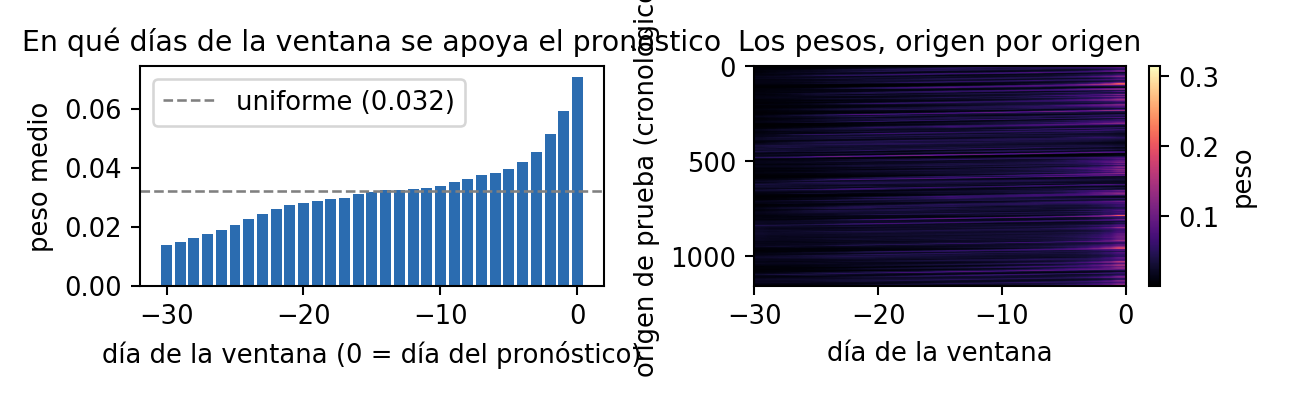

In [20]:
# ============================================================
# 11. Los pesos de atención del modelo final
# ============================================================
# Un submodelo que devuelve la capa de atención en vez del pronóstico. Es el MISMO modelo entrenado:
# solo se le pide una salida intermedia.
lector = keras.Model(modelo_final.inputs, modelo_final.get_layer("atencion").output)
# `escalar` devuelve (ajuste, evaluación) en ese orden: lo que hace falta aquí es el SEGUNDO, las
# ventanas de los orígenes de prueba, escaladas con la media y la desviación del último bloque de
# ajuste. Quedarse con el primero mezcla 5.633 filas de ajuste con 1.155 estáticas de prueba.
_, X_pr = escalar(indices_ajuste(ORIGENES_PRUEBA[-PASO_WFV]), I_PRUEBA)
assert len(X_pr) == len(I_PRUEBA), f"se escalaron {len(X_pr)} ventanas y hay {len(I_PRUEBA)}"
A = lector.predict([X_pr, ESTATICAS[I_PRUEBA].astype("float32")], verbose=0)[:, :, 0]
assert A.shape == (len(I_PRUEBA), VENTANA), A.shape
assert np.allclose(A.sum(axis=1), 1.0, atol=1e-5), "los pesos de atención no suman 1"

dias = np.arange(-(VENTANA - 1), 1)          # -30 .. 0, donde 0 es el día del origen
media = A.mean(axis=0)
unif = 1 / VENTANA
print(f"Pesos de atención, media sobre los {len(I_PRUEBA)} orígenes de prueba:")
print(f"  uniforme sería {unif:.4f} para cada uno de los {VENTANA} días")
print(f"  máximo {media.max():.4f} en el día {dias[media.argmax()]:+d}  |  "
      f"mínimo {media.min():.4f} en el día {dias[media.argmin()]:+d}")
print(f"  los 7 últimos días concentran {100 * media[-7:].sum():.1f} % del peso "
      f"(uniforme: {100 * 7 / VENTANA:.1f} %)")
print(f"  desviación respecto de lo uniforme: {np.abs(media - unif).sum() / 2:.3f} "
      f"(0 = plana, 1 = todo el peso en un solo día)")
print(f"  variación entre orígenes: la desviación típica del peso del día 0 es "
      f"{A[:, -1].std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].bar(dias, media, color="#2b6cb0")
axes[0].axhline(unif, ls="--", c="gray", lw=1, label=f"uniforme ({unif:.3f})")
axes[0].set_xlabel("día de la ventana (0 = día del pronóstico)")
axes[0].set_ylabel("peso medio")
axes[0].set_title("En qué días de la ventana se apoya el pronóstico")
axes[0].legend()
im = axes[1].imshow(A, aspect="auto", cmap="magma",
                    extent=[dias[0], dias[-1], len(I_PRUEBA), 0])
axes[1].set_xlabel("día de la ventana")
axes[1].set_ylabel("origen de prueba (cronológico)")
axes[1].set_title("Los pesos, origen por origen")
fig.colorbar(im, ax=axes[1], label="peso")
a_escala(fig)
plt.tight_layout()
plt.show()

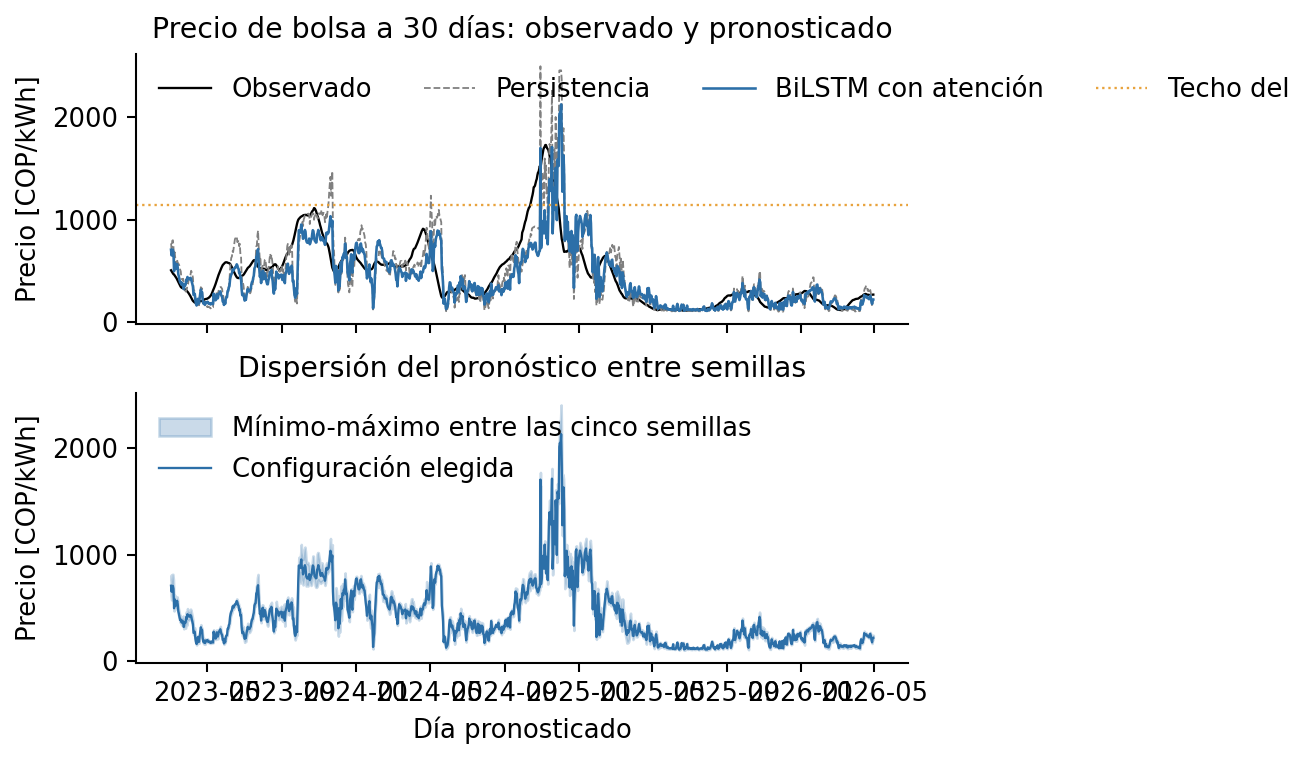

Techo del entrenamiento: 1147.9 COP/kWh
El pronóstico llega a 2127 COP/kWh y supera ese techo en 23 de los 1155 días pronosticados.
Amplitud media de la banda entre las cinco semillas: 66.6 COP/kWh


In [21]:
# ============================================================
# 12.1 El pronóstico sobre el periodo de prueba
# ============================================================
# ESTA ES LA FIGURA QUE VA AL DOCUMENTO, y la dibuja `_figuras.pronostico`, que es el mismo código
# para las cinco familias. Si cada cuaderno la dibujara por su cuenta, a la primera corrección en
# uno solo de ellos las figuras dejarían de ser comparables sin que nada avisara, y comparar
# familias es justamente lo que el trabajo hace.
#
# NO SE REENTRENA NI SE LEE NADA: se dibuja `pred_guardar`, que es lo que la celda anterior acaba
# de guardar como el archivo de predicciones. El techo del entrenamiento sí se lee del dataset de
# selección, para que las cinco familias marquen exactamente la misma línea.
from _figuras import pronostico, techo_entrenamiento, PROPORCION_PRONOSTICO

TECHO = techo_entrenamiento(PROC, FIN_ENTRENAMIENTO)
fig, datos = pronostico(pred_guardar, MEJOR, "Híbrido semilla ", "BiLSTM con atención", TECHO,
                        a_escala, ANCHO_PAGINA, alto_pagina(*PROPORCION_PRONOSTICO))
plt.show();

print(f"Techo del entrenamiento: {datos['techo']:.1f} COP/kWh")
print(f"El pronóstico llega a {datos['maximo_pronosticado']:.0f} COP/kWh y supera ese techo en "
      f"{datos['dias_sobre_techo']} de los {len(pred_guardar)} días pronosticados.")
print(f"Amplitud media de la banda entre las cinco semillas: {datos['amplitud_banda']:.1f} COP/kWh")

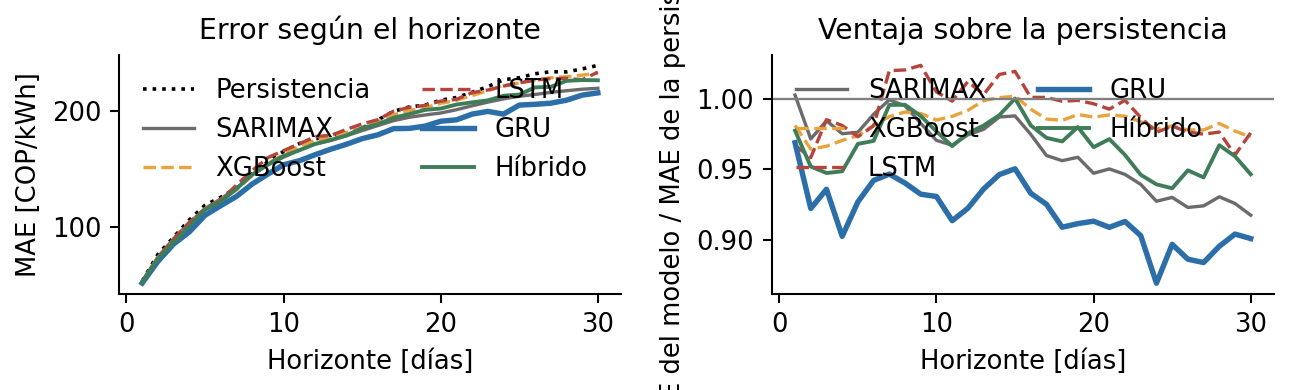

Razón frente a la persistencia, por familia:
  SARIMAX   h=1 1.002  h=30 0.917  pierde en 1 de los 30 horizontes
  XGBoost   h=1 0.981  h=30 0.973  pierde en 2 de los 30 horizontes
  LSTM      h=1 0.967  h=30 0.976  pierde en 10 de los 30 horizontes
  GRU       h=1 0.969  h=30 0.901  pierde en 0 de los 30 horizontes
  Híbrido   h=1 0.977  h=30 0.946  pierde en 0 de los 30 horizontes


In [22]:
# ============================================================
# 12.2 Las cinco familias frente al horizonte
# ============================================================
# La figura que cierra la comparación, y va aquí porque este es el último cuaderno de la cadena:
# el único que tiene en disco los cinco archivos de error por horizonte, incluido el suyo, que la
# celda anterior acaba de escribir.
from _figuras import comparativa_horizonte, PROPORCION_HORIZONTE

fig, resumen = comparativa_horizonte(PROC, a_escala, ANCHO_PAGINA,
                                     alto_pagina(*PROPORCION_HORIZONTE))
plt.show();

print("Razón frente a la persistencia, por familia:")
for nombre, d in resumen.items():
    print(f"  {nombre:<9} h=1 {d['razon_h1']:.3f}  h=30 {d['razon_h30']:.3f}  "
          f"pierde en {d['horizontes_que_pierde']} de los {d['n']} horizontes")

## 13. Conclusiones y limitaciones

*Las cifras de esta sección se leen de las salidas de arriba.

### Lo que se encontró

**El híbrido queda tercero de los cinco.** Mejora a la LSTM y al XGBoost, y no alcanza al GRU ni al SARIMAX.

| Modelo | MAE | SMAPE |
|---|---|---|
| **GRU** | **132,47** | **26,75** |
| SARIMAX | 136,70 | 28,66 |
| **Híbrido** | **140,17** | **28,86** |
| XGBoost | 143,10 | 30,19 |
| LSTM | 144,83 | 31,09 |
| Persistencia | 145,66 | 30,54 |

### Ningún modelo gana en todas partes

Esta es la lectura que importa para el capítulo de resultados, y el híbrido la hace visible.

| | El Niño | Neutral | La Niña | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|---|
| Mejor modelo | SARIMAX | GRU | GRU | **Híbrido** | SARIMAX | GRU | GRU |

### Lo que la atención deja ver, que es lo único interpretable de esta familia

Los pesos **no son uniformes**, y eso ya es un resultado: si la red no hubiera aprendido a discriminar, los 31 días valdrían 0,0323 cada uno.

- El máximo está en el **día 0**, el del pronóstico, con 0,0708: más del doble de lo uniforme.
- El mínimo está en el **día −30**, el más antiguo de la ventana, con 0,0139.
- Los **siete últimos días concentran el 34,6 %** del peso, cuando lo uniforme sería 22,6 %.
- La desviación respecto de lo uniforme es 0,136, en una escala donde 0 es plana y 1 sería todo el peso en un solo día.
- Y **no es una regla fija**: la desviación típica del peso del día 0 entre orígenes es 0,0443, de modo que la red reparte distinto según el origen.

### La descomposición: por qué ayudó menos de lo esperado

La tabla de la sección 3.4 lo explica.

### Limitaciones que conviene declarar

- **El grano de la entrada no es el mismo que el de las otras dos familias.** La ventana da a la red los treinta valores diarios individuales; los árboles los vieron agregados en medias y rezagos.
- **El escalador se reajusta por bloque, y el nivel del precio se multiplica por 2,43 entre entrenamiento y prueba.** La escala logarítmica comprime ese salto, pero no lo elimina: en los bloques iniciales de la prueba la red recibe entradas desplazadas respecto….
- **El número de épocas se elige sobre pliegues más pequeños que los bloques de la corrida final.** Los conjuntos de ajuste de los cinco pliegues van de 886 a 3.808 orígenes, y los de la validación progresiva empiezan en 4.568.
- **La rejilla recorre tres arquitecturas y seis valores de épocas**, elegidos por criterio y no por barrido.
- **El coste de cómputo es el más alto de las cuatro familias.**
- **No se produce pronóstico probabilístico.**
- **Los tres mecanismos entran juntos y no se pueden separar.**
- **La descomposición es parcial en los seis primeros días de cada ventana.** La media móvil de siete días hacia atrás no está completa ahí, y la sección 3.4 mide el error que eso introduce sobre una señal de perfil conocido.
- **Los pesos de atención que se grafican son los del último reajuste**, leídos sobre todos los orígenes de prueba con el escalador de ese bloque.
- **La familia de los híbridos queda representada por uno solo.**

### Siguiente paso

Ninguno dentro del modelado.